
# Detección y análisis del color dominante en imágenes digitales de naranjas
**Estudiante** Camilo Eduardo Muñoz Albornoz  
**Universidad Tecnológica de Pereira**  
**Asignatura:** Procesamiento Digital de Imágenes

## 1. Introducción

El procesamiento digital de imágenes permite extraer información de los objetos representados en una fotografía mediante operaciones sobre sus píxeles.

En este proyecto se desarrolla un algoritmo para detectar una naranja, separar su superficie del fondo y determinar su color RGB promedio y el rango RGB predominante.

Se utilizan técnicas clásicas como filtrado espacial, umbralización, segmentación en HSV, operaciones morfológicas, detección de contornos y cuantización de colores.

### Objetivo general

Desarrollar un algoritmo en Python que permita identificar el contorno de una naranja y determinar su color RGB promedio y el rango de color más frecuente a partir de imágenes digitales.

### Objetivos específicos

1. Segmentar la región correspondiente a la fruta mediante técnicas de procesamiento digital de imágenes.
2. Identificar el contorno y establecer la región de interés (ROI).
3. Calcular el color RGB promedio y determinar el rango RGB dominante.
4. Representar visualmente la fruta utilizando su color predominante.
5. Evaluar el funcionamiento del algoritmo mediante fotografías con diferentes tonalidades y condiciones de captura.

### Alcance

El algoritmo procesa fotografías que contienen una naranja individual, principalmente sobre fondos claros. Se evalúa su comportamiento ante variaciones de color, iluminación y presencia de sombras.

El sistema no determina automáticamente la madurez ni el estado sanitario de la fruta. Su finalidad es analizar el color visible en las imágenes digitales.



## 2. Conjunto de imágenes y metodología


### Procedencia de las fotografías

Se utilizaron 50 fotografías seleccionadas para el proyecto.

De ellas, **48 fueron seleccionadas del conjunto público de imágenes de naranjas disponible en Mendeley Data**. Las dos fotografías restantes, `naranja01.jpg` y `naranajaSombra.png`, se obtuvieron de fuentes disponibles en internet y se utilizaron exclusivamente durante el desarrollo del algoritmo.

El conjunto de desarrollo contiene cinco fotografías y el conjunto de evaluación contiene 45 fotografías.

**Fuente principal:** [Orange Fruit Image Dataset — Mendeley Data](https://data.mendeley.com/datasets/zk4hzhtcdd/2)


### Configuración del procesamiento

| Parámetro | Valor |
|---|---|
| Lenguaje | Python |
| Biblioteca principal | OpenCV |
| Dimensión máxima | 800 píxeles por lado |
| Filtrado | Gaussiano 5 × 5 |
| Segmentación | Canal de saturación HSV |
| Umbral de saturación | 50->120 luego de pruebas |
| Morfología | Cierre con elemento elíptico 5 × 5 |
| Contornos | Mayor contorno exterior |
| Análisis de color | RGB |
| Cuantización | Intervalos de 32 niveles por canal |

Los parámetros se establecieron durante el desarrollo y se mantuvieron constantes en el conjunto de evaluación.



### Requisitos de ejecución

El notebook requiere Python 3 y las bibliotecas `opencv-python`, `numpy`, `matplotlib` y `pandas`.

Se debe ejecutar desde la carpeta principal del proyecto, conservando la estructura de directorios `dataset/desarrollo`, `dataset/evaluacion` y `resultados`.


In [1]:
# --------------------------------------------------
# 1. IMPORTACIÓN DE BIBLIOTECAS Y CONFIGURACIÓN
# --------------------------------------------------

from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Path.cwd() obtiene el directorio de trabajo actual.
# El notebook debe ejecutarse desde la carpeta raíz del proyecto.
BASE_DIR = Path.cwd()

# Carpeta con las fotografías utilizadas para desarrollar el algoritmo.
RUTA_DESARROLLO = BASE_DIR / "dataset" / "desarrollo"

# Carpeta con las 45 imágenes reservadas para evaluación.
RUTA_EVALUACION = BASE_DIR / "dataset" / "evaluacion"

# Carpeta donde guardaremos tablas y figuras.
RUTA_RESULTADOS = BASE_DIR / "resultados"
RUTA_RESULTADOS.mkdir(parents=True, exist_ok=True)

# Fotografía utilizada para explicar paso a paso el procesamiento.
RUTA_IMAGEN = RUTA_DESARROLLO / "naranja01.jpg"

# Parámetros establecidos durante el desarrollo.
TAMANO_MAXIMO = 800
# Umbral utilizado en el desarrollo inicial del algoritmo.
UMBRAL_S = 50
INTERVALO_RGB = 32

# Verificamos que existan las carpetas y la imagen de ejemplo.
if not RUTA_IMAGEN.is_file():
    raise FileNotFoundError(
        f"No se encontró la imagen de ejemplo: {RUTA_IMAGEN}"
    )

if not RUTA_EVALUACION.is_dir():
    raise FileNotFoundError(
        f"No se encontró la carpeta de evaluación: {RUTA_EVALUACION}"
    )

print("Proyecto:", BASE_DIR)
print("OpenCV:", cv2.__version__)
print("Imagen de ejemplo:", RUTA_IMAGEN.name)
print("Configuración inicial correcta.")


Proyecto: d:\SistemasUniversidad\sistemas8\ProcDImagenes\deteccion_colores_naranjas
OpenCV: 5.0.0
Imagen de ejemplo: naranja01.jpg
Configuración inicial correcta.



## 3. Lectura y representación de la imagen digital

Una imagen digital en color se representa mediante una matriz tridimensional de dimensiones `(alto, ancho, 3)`. Cada píxel almacena tres componentes correspondientes a los canales rojo, verde y azul (RGB).

En imágenes de 8 bits por canal, cada componente tiene valores entre 0 y 255.

OpenCV utiliza habitualmente el orden BGR al leer imágenes, por lo que es necesario convertirlas a RGB para visualizarlas correctamente con Matplotlib y realizar el análisis de color.

Para reducir el costo computacional, se redimensionan las imágenes cuyo lado mayor supera los 800 píxeles, conservando su proporción. Las fotografías originales no se modifican.


Resolución original: 2048 x 2048
Resolución de procesamiento: 800 x 800
Número de canales: 3
Tipo de datos: uint8
Píxel central RGB: [248 154   0]


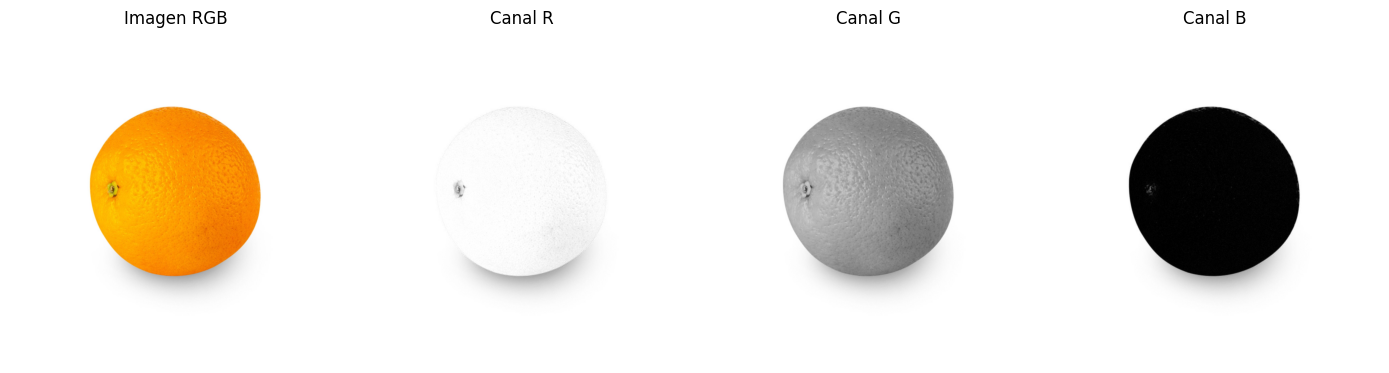

In [2]:

# --------------------------------------------------
# 3. LECTURA Y REPRESENTACIÓN DE LA IMAGEN DIGITAL
# --------------------------------------------------

# imread() lee la fotografía y devuelve una matriz NumPy.
# OpenCV almacena sus canales en orden BGR.
imagen_bgr = cv2.imread(str(RUTA_IMAGEN))

if imagen_bgr is None:
    raise ValueError("No fue posible leer la fotografía.")

# Convertimos BGR a RGB para interpretar correctamente los colores.
imagen_rgb_original = cv2.cvtColor(
    imagen_bgr, cv2.COLOR_BGR2RGB
)

# Obtenemos el alto, ancho y número de canales.
alto_original, ancho_original, canales = imagen_rgb_original.shape

# Calculamos un factor de escala que no aumente la resolución.
escala = min(
    1.0,
    TAMANO_MAXIMO / max(alto_original, ancho_original)
)

# resize() modifica las dimensiones de la matriz.
# INTER_AREA es adecuado para reducir imágenes.
if escala < 1:
    imagen_rgb = cv2.resize(
        imagen_rgb_original,
        None,
        fx=escala,
        fy=escala,
        interpolation=cv2.INTER_AREA
    )
else:
    imagen_rgb = imagen_rgb_original.copy()

alto, ancho = imagen_rgb.shape[:2]

print(f"Resolución original: {ancho_original} x {alto_original}")
print(f"Resolución de procesamiento: {ancho} x {alto}")
print(f"Número de canales: {canales}")
print(f"Tipo de datos: {imagen_rgb.dtype}")
print(f"Píxel central RGB: {imagen_rgb[alto//2, ancho//2]}")

# Extraemos los canales individuales de la imagen.
# Cada canal es una matriz bidimensional.
R, G, B = cv2.split(imagen_rgb)

# Mostramos la imagen y los tres canales en escala de grises.
fig, ax = plt.subplots(1, 4, figsize=(14, 4))

imagenes = [imagen_rgb, R, G, B]
titulos = ["Imagen RGB", "Canal R", "Canal G", "Canal B"]

for i in range(4):
    if i == 0:
        ax[i].imshow(imagenes[i])
    else:
        ax[i].imshow(imagenes[i], cmap="gray", vmin=0, vmax=255)

    ax[i].set_title(titulos[i])
    ax[i].axis("off")

plt.tight_layout()
plt.show()



## 4. Preprocesamiento y segmentación de la fruta

El preprocesamiento prepara la imagen para facilitar la identificación del objeto.

**Filtrado gaussiano:** es un filtro espacial pasa-bajos que suaviza pequeñas variaciones de intensidad mediante un promedio ponderado de los píxeles vecinos. Se utiliza un núcleo de 5 × 5.

**Escala de grises:** transforma los tres canales RGB en uno de intensidad, permitiendo realizar una umbralización basada en la luminosidad.

**Umbralización:** clasifica los píxeles según un valor límite y genera una máscara binaria.

Inicialmente se compara la umbralización inversa en escala de grises con la segmentación basada en el canal de saturación (S) del espacio HSV.

Se utiliza HSV porque permite separar el tono, la saturación y la luminosidad. En nuestras fotografías, la cáscara suele presentar mayor saturación que el fondo blanco.

La comparación permite justificar la elección del método de segmentación.


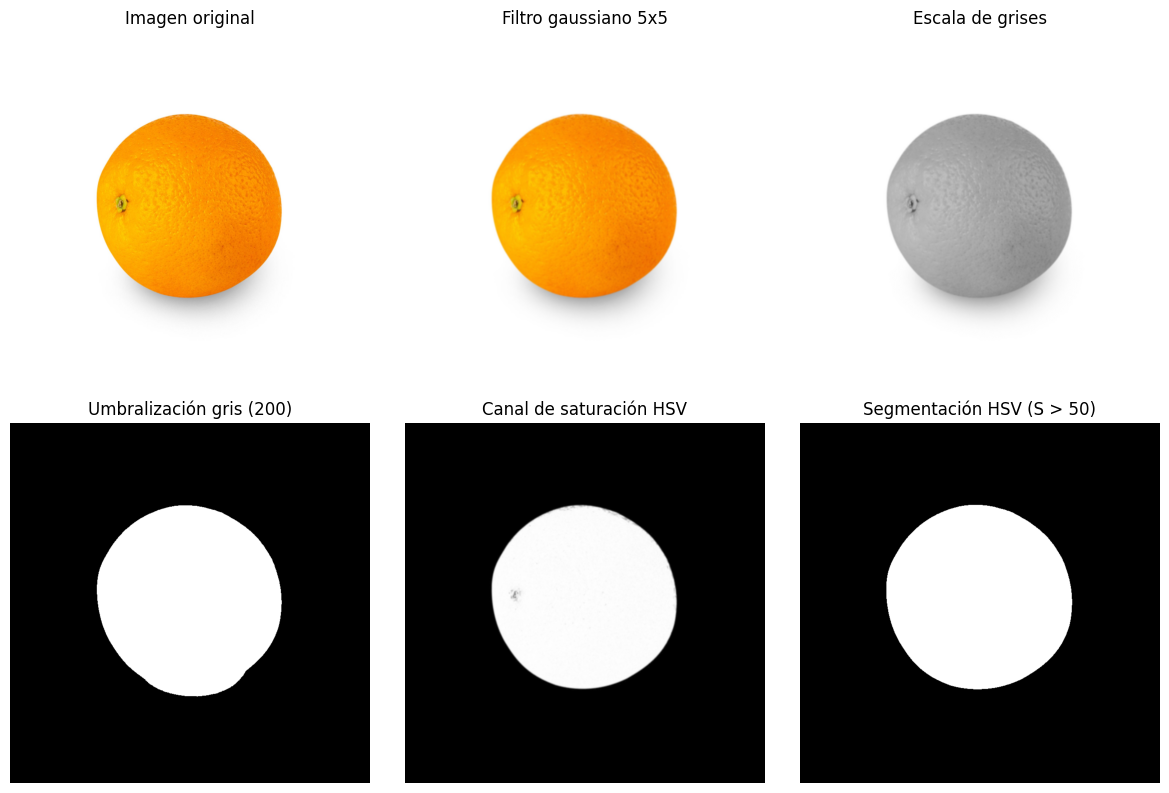

In [3]:

# --------------------------------------------------
# 4. PREPROCESAMIENTO Y COMPARACIÓN DE SEGMENTACIÓN
# --------------------------------------------------

# 1. FILTRADO GAUSSIANO
# GaussianBlur() aplica un promedio ponderado de píxeles vecinos.
# El núcleo 5x5 suaviza pequeñas variaciones y reduce ruido.
# El valor sigma=0 permite que OpenCV lo calcule automáticamente.
imagen_suavizada = cv2.GaussianBlur(
    imagen_rgb, (5, 5), 0
)

# 2. CONVERSIÓN A ESCALA DE GRISES
# cvtColor() transforma los tres canales RGB en uno de intensidad.
imagen_gris = cv2.cvtColor(
    imagen_suavizada, cv2.COLOR_RGB2GRAY
)

# 3. UMBRALIZACIÓN EN ESCALA DE GRISES
# THRESH_BINARY_INV asigna 255 a intensidades <= 200 y 0 al resto.
# Se incluye como método de comparación, no como solución definitiva.
_, mascara_gris = cv2.threshold(
    imagen_gris, 200, 255, cv2.THRESH_BINARY_INV
)

# 4. CONVERSIÓN AL ESPACIO HSV
# H representa el tono, S la saturación y V la luminosidad.
imagen_hsv = cv2.cvtColor(
    imagen_suavizada, cv2.COLOR_RGB2HSV
)

# Extraemos el canal S (índice 1).
# En OpenCV, para imágenes HSV de 8 bits, S varía entre 0 y 255.
saturacion = imagen_hsv[:, :, 1]

# 5. UMBRALIZACIÓN SOBRE LA SATURACIÓN
# THRESH_BINARY asigna 255 cuando S > 50 y 0 en caso contrario.
# Esta será nuestra técnica principal de segmentación.
_, mascara_hsv = cv2.threshold(
    saturacion, UMBRAL_S, 255, cv2.THRESH_BINARY
)

# 6. VISUALIZACIÓN COMPARATIVA
fig, ax = plt.subplots(2, 3, figsize=(12, 8))

visualizaciones = [
    (imagen_rgb, "Imagen original", None),
    (imagen_suavizada, "Filtro gaussiano 5x5", None),
    (imagen_gris, "Escala de grises", "gray"),
    (mascara_gris, "Umbralización gris (200)", "gray"),
    (saturacion, "Canal de saturación HSV", "gray"),
    (mascara_hsv, "Segmentación HSV (S > 50)", "gray")
]

for eje, (imagen, titulo, mapa_color) in zip(
    ax.flat, visualizaciones
):
    if mapa_color is None:
        eje.imshow(imagen)
    else:
        eje.imshow(imagen, cmap=mapa_color, vmin=0, vmax=255)

    eje.set_title(titulo)
    eje.axis("off")

plt.tight_layout()
plt.show()



## 5. Operaciones morfológicas y detección de contornos

Las operaciones morfológicas permiten modificar la forma de las regiones de una imagen binaria mediante un elemento estructurante o *kernel*.

En nuestra máscara, los píxeles blancos (255) representan las regiones detectadas y los negros (0) representan el fondo.

Las principales operaciones son:

- **Erosión:** reduce las regiones blancas y puede eliminar pequeños objetos aislados.
- **Dilatación:** expande las regiones blancas y puede conectar regiones cercanas.
- **Apertura:** aplica erosión seguida de dilatación. Es útil para eliminar pequeñas regiones blancas.
- **Cierre:** aplica dilatación seguida de erosión. Es útil para cerrar pequeñas discontinuidades y rellenar huecos pequeños.

Para el algoritmo definitivo se utiliza un **cierre morfológico con un elemento estructurante elíptico de 5 × 5**, con el propósito de mejorar la continuidad de la máscara.

Posteriormente, se identifican los contornos exteriores y se selecciona el de mayor área, bajo el supuesto de que la naranja es el objeto principal de la fotografía.


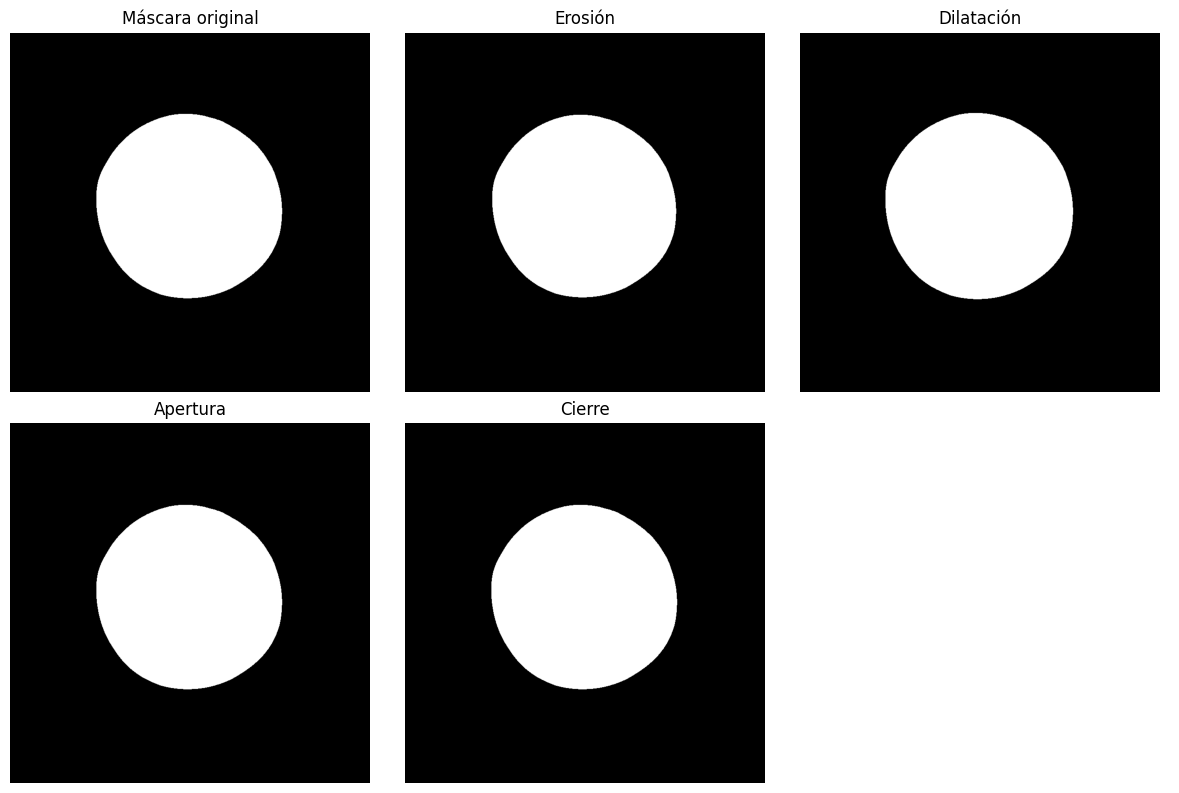

Elemento estructurante utilizado:
[[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]


In [4]:

# --------------------------------------------------
# 5. OPERACIONES MORFOLÓGICAS
# --------------------------------------------------

# Creamos un elemento estructurante de forma elíptica.
# Sus dimensiones son de 5 x 5 píxeles.
kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (5, 5)
)

# EROSIÓN:
# Reduce las regiones blancas de la máscara.
mascara_erosion = cv2.erode(
    mascara_hsv, kernel, iterations=1
)

# DILATACIÓN:
# Expande las regiones blancas de la máscara.
mascara_dilatacion = cv2.dilate(
    mascara_hsv, kernel, iterations=1
)

# APERTURA:
# Primero erosiona y después dilata.
# Puede eliminar pequeñas regiones blancas aisladas.
mascara_apertura = cv2.morphologyEx(
    mascara_hsv, cv2.MORPH_OPEN, kernel
)

# CIERRE:
# Primero dilata y después erosiona.
# Puede cerrar discontinuidades y huecos pequeños.
# ESTA es la operación usada en el algoritmo definitivo.
mascara_cierre = cv2.morphologyEx(
    mascara_hsv, cv2.MORPH_CLOSE, kernel
)

# Comparación visual de las operaciones.
fig, ax = plt.subplots(2, 3, figsize=(12, 8))

comparaciones = [
    (mascara_hsv, "Máscara original"),
    (mascara_erosion, "Erosión"),
    (mascara_dilatacion, "Dilatación"),
    (mascara_apertura, "Apertura"),
    (mascara_cierre, "Cierre")
]

for eje, (imagen, titulo) in zip(ax.flat, comparaciones):
    eje.imshow(imagen, cmap="gray", vmin=0, vmax=255)
    eje.set_title(titulo)
    eje.axis("off")

# Ocultamos el espacio sobrante.
ax.flat[-1].axis("off")

plt.tight_layout()
plt.show()

print("Elemento estructurante utilizado:")
print(kernel)


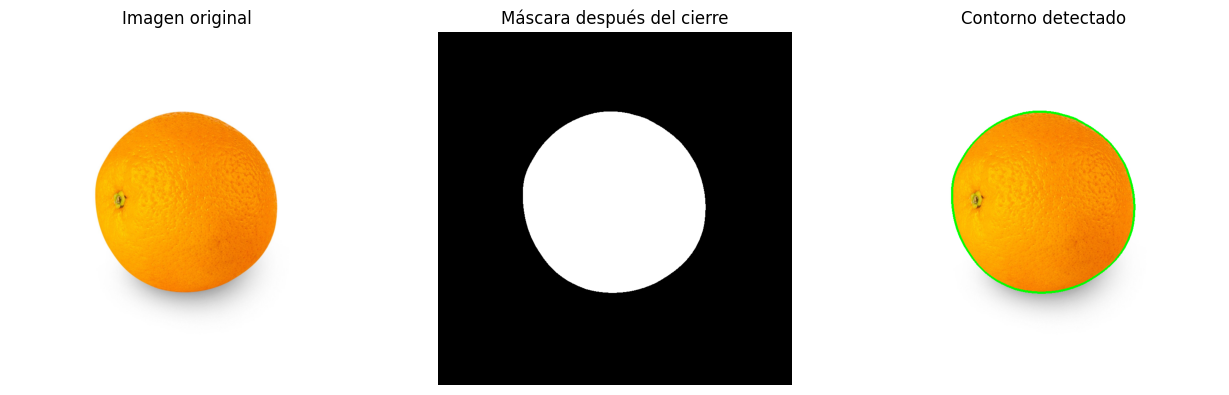

Contornos exteriores encontrados: 1
Área del contorno principal: 132079 píxeles²


In [5]:

# --------------------------------------------------
# 5.1. DETECCIÓN DEL CONTORNO DE LA FRUTA
# --------------------------------------------------

# findContours() identifica los límites de las regiones blancas.
#
# RETR_EXTERNAL: recupera solamente los contornos exteriores.
# CHAIN_APPROX_SIMPLE: reduce puntos redundantes del contorno.
contornos, _ = cv2.findContours(
    mascara_cierre,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

if not contornos:
    raise ValueError("No se encontraron contornos en la imagen.")

# Elegimos el contorno de mayor área.
# Suponemos que la naranja es el objeto principal.
contorno_principal = max(
    contornos,
    key=cv2.contourArea
)

# Calculamos el área del contorno en píxeles cuadrados.
area_contorno = cv2.contourArea(contorno_principal)

# Copiamos la imagen para dibujar sin modificar la original.
imagen_contorno = imagen_rgb.copy()

# Dibujamos el contorno en color verde.
# -1: dibuja el único contorno de la lista.
# (0, 255, 0): verde, porque la imagen está en RGB.
# 3: grosor de la línea.
cv2.drawContours(
    imagen_contorno,
    [contorno_principal],
    -1,
    (0, 255, 0),
    3
)

# Mostramos la máscara y el resultado.
fig, ax = plt.subplots(1, 3, figsize=(13, 4))

ax[0].imshow(imagen_rgb)
ax[0].set_title("Imagen original")

ax[1].imshow(mascara_cierre, cmap="gray", vmin=0, vmax=255)
ax[1].set_title("Máscara después del cierre")

ax[2].imshow(imagen_contorno)
ax[2].set_title("Contorno detectado")

for eje in ax:
    eje.axis("off")

plt.tight_layout()
plt.show()

print(f"Contornos exteriores encontrados: {len(contornos)}")
print(f"Área del contorno principal: {area_contorno:.0f} píxeles²")



## 6. Región de interés y análisis del color RGB

Una vez identificado el contorno principal, se construye una **región de interés (ROI)** que contiene los píxeles de la fruta.

Para ello se crea una máscara binaria del mismo tamaño que la imagen y se rellena el interior del contorno seleccionado. Los píxeles blancos representan la región que será analizada.

### Color RGB promedio

Se calcula la media aritmética de cada canal RGB utilizando todos los píxeles de la ROI. Este valor resume el color general de la región segmentada.

### Rango RGB dominante

Para identificar los colores más frecuentes se utiliza una cuantización RGB con intervalos de 32 niveles por canal.

Cada canal de 8 bits se divide en ocho intervalos, obteniendo 512 combinaciones posibles de rangos RGB.

Se identifica la combinación que contiene más píxeles y se calcula su frecuencia relativa. Después se obtiene un color representativo promediando los píxeles que pertenecen a ese intervalo.

El porcentaje dominante representa la proporción de píxeles incluidos en el intervalo RGB más frecuente, no la precisión del algoritmo ni el porcentaje de superficie que una persona percibe como un determinado color.


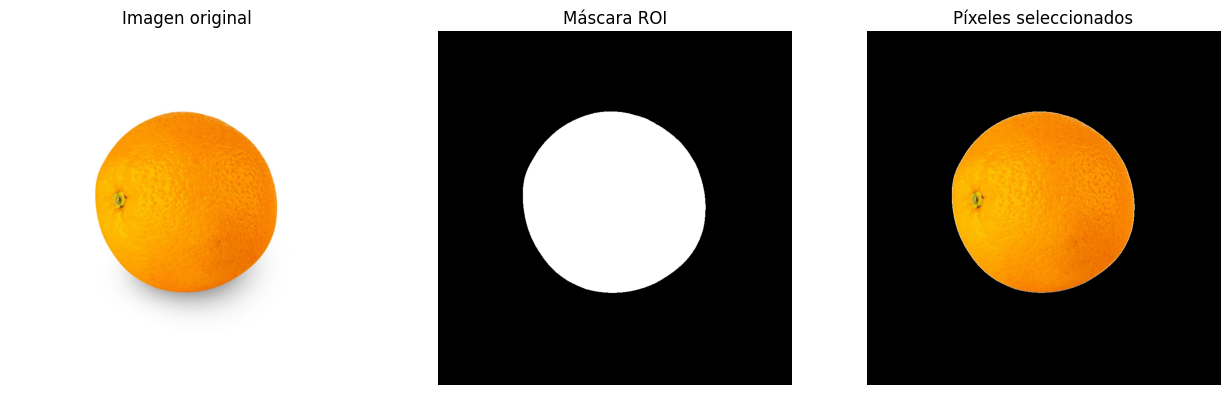

Píxeles de la ROI: 132,660
RGB promedio: [249.32 152.19   5.27]


In [6]:

# --------------------------------------------------
# 6.1. CREACIÓN DE LA ROI Y CÁLCULO DEL RGB PROMEDIO
# --------------------------------------------------

# Creamos una máscara negra con las mismas dimensiones
# espaciales de la imagen RGB.
mascara_roi = np.zeros(
    imagen_rgb.shape[:2],
    dtype=np.uint8
)

# Rellenamos de blanco el interior del contorno principal.
# FILLED indica que se dibuje la región completa.
cv2.drawContours(
    mascara_roi,
    [contorno_principal],
    -1,
    255,
    cv2.FILLED
)

# bitwise_and conserva la imagen donde la máscara vale 255.
# Los píxeles externos quedan negros.
imagen_roi = cv2.bitwise_and(
    imagen_rgb,
    imagen_rgb,
    mask=mascara_roi
)

# Seleccionamos solo los píxeles pertenecientes a la fruta.
# El resultado es una matriz con una fila por píxel
# y tres columnas: R, G y B.
pixeles_roi = imagen_rgb[mascara_roi > 0]

# Calculamos la media de cada canal.
# axis=0 significa calcular la media por columna.
rgb_promedio = np.mean(pixeles_roi, axis=0)

# Visualización.
fig, ax = plt.subplots(1, 3, figsize=(13, 4))

ax[0].imshow(imagen_rgb)
ax[0].set_title("Imagen original")

ax[1].imshow(mascara_roi, cmap="gray", vmin=0, vmax=255)
ax[1].set_title("Máscara ROI")

ax[2].imshow(imagen_roi)
ax[2].set_title("Píxeles seleccionados")

for eje in ax:
    eje.axis("off")

plt.tight_layout()
plt.show()

print(f"Píxeles de la ROI: {len(pixeles_roi):,}")
print(f"RGB promedio: {np.round(rgb_promedio, 2)}")


In [7]:

# --------------------------------------------------
# 6.2. CUANTIZACIÓN Y COLOR RGB DOMINANTE
# --------------------------------------------------

# Dividimos cada canal RGB en intervalos de 32 niveles.
# astype(int32) facilita trabajar con valores enteros.
#
# Ejemplo: RGB (250, 150, 10) -> grupo (7, 4, 0).
grupos_rgb = pixeles_roi.astype(np.int32) // INTERVALO_RGB

# np.unique() identifica las combinaciones RGB existentes.
# axis=0 compara filas completas: grupos (R, G, B).
# return_counts=True devuelve la frecuencia de cada grupo.
grupos_unicos, frecuencias = np.unique(
    grupos_rgb,
    axis=0,
    return_counts=True
)

# Identificamos el grupo más frecuente.
indice_dominante = np.argmax(frecuencias)

grupo_dominante = grupos_unicos[indice_dominante]
frecuencia_dominante = frecuencias[indice_dominante]

# Calculamos los límites RGB del intervalo dominante.
rango_inferior = grupo_dominante * INTERVALO_RGB

rango_superior = np.minimum(
    rango_inferior + INTERVALO_RGB - 1,
    255
)

# Identificamos cuáles píxeles pertenecen a ese grupo.
seleccion_dominante = np.all(
    grupos_rgb == grupo_dominante,
    axis=1
)

# Calculamos un color representativo del intervalo dominante.
# Promediamos únicamente los píxeles incluidos en ese grupo.
rgb_dominante = np.mean(
    pixeles_roi[seleccion_dominante],
    axis=0
)

# Porcentaje de píxeles en el intervalo más frecuente.
porcentaje_dominante = (
    frecuencia_dominante / len(pixeles_roi)
) * 100

print("Grupo dominante:", grupo_dominante)
print("Rango RGB inferior:", rango_inferior)
print("Rango RGB superior:", rango_superior)
print("Frecuencia dominante:", frecuencia_dominante)
print(f"Porcentaje dominante: {porcentaje_dominante:.2f} %")
print("RGB representativo:", np.round(rgb_dominante, 2))


Grupo dominante: [7 4 0]
Rango RGB inferior: [224 128   0]
Rango RGB superior: [255 159  31]
Frecuencia dominante: 72431
Porcentaje dominante: 54.60 %
RGB representativo: [250.11 143.7    2.93]


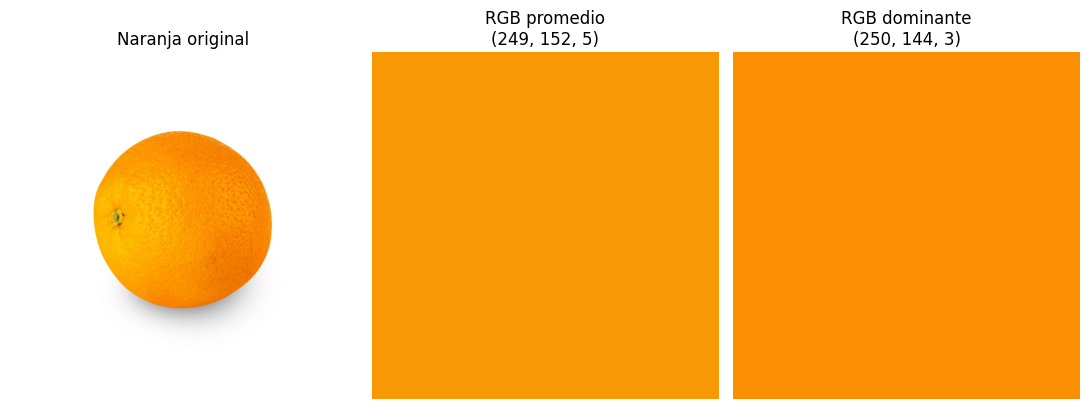

In [8]:

# --------------------------------------------------
# 6.3. VISUALIZACIÓN DE LOS COLORES CALCULADOS
# --------------------------------------------------

# Convertimos los valores RGB a números entre 0 y 1,
# formato que Matplotlib acepta para definir colores.
color_promedio = rgb_promedio / 255
color_dominante = rgb_dominante / 255

fig, ax = plt.subplots(1, 3, figsize=(11, 4))

# Fotografía original.
ax[0].imshow(imagen_rgb)
ax[0].set_title("Naranja original")

# Muestra del color promedio.
ax[1].imshow(
    np.ones((100, 100, 3)) * color_promedio
)
ax[1].set_title(
    f"RGB promedio\n"
    f"{tuple(int(round(v)) for v in rgb_promedio)}"
)

# Muestra del color dominante.
ax[2].imshow(
    np.ones((100, 100, 3)) * color_dominante
)
ax[2].set_title(
    f"RGB dominante\n"
    f"{tuple(int(round(v)) for v in rgb_dominante)}"
)

for eje in ax:
    eje.axis("off")

plt.tight_layout()
plt.show()



## 7. Representación visual del color dominante

Para visualizar el resultado del análisis, se genera una copia de la fotografía y se reemplazan los píxeles de la región de interés por el color RGB dominante.

La operación conserva las dimensiones originales de la imagen procesada y modifica únicamente los píxeles incluidos en la máscara ROI.

De esta manera, la superficie de la fruta aparece representada mediante un color uniforme, mientras el fondo permanece sin cambios.

Esta representación permite observar el color predominante estimado y verificar visualmente la región segmentada.


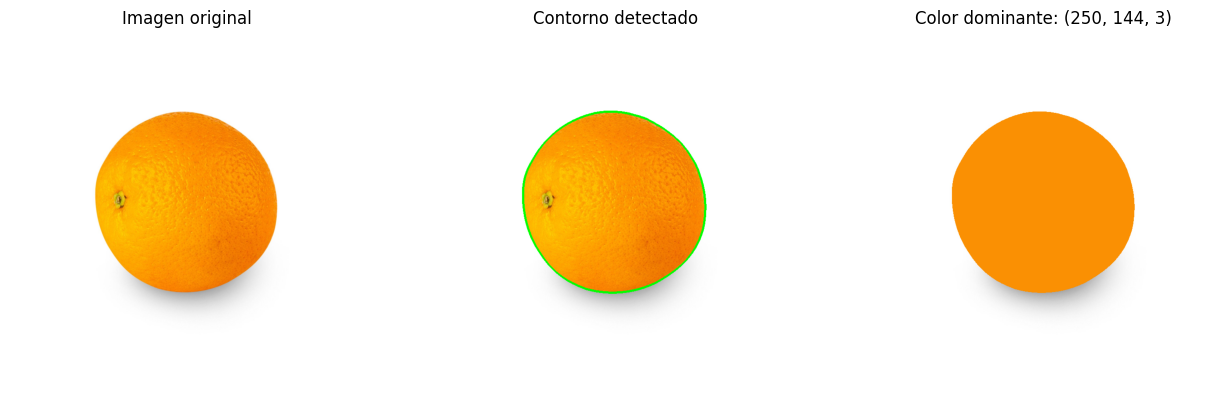

In [9]:

# --------------------------------------------------
# 7. REPINTADO DE LA NARANJA CON SU COLOR DOMINANTE
# --------------------------------------------------

# Creamos una copia para conservar la fotografía original.
imagen_repintada = imagen_rgb.copy()

# Redondeamos el RGB dominante y lo convertimos a uint8.
# Una imagen de 8 bits requiere valores enteros entre 0 y 255.
rgb_dominante_entero = np.round(
    rgb_dominante
).astype(np.uint8)

# Reemplazamos únicamente los píxeles de la ROI.
# Los píxeles del fondo permanecen sin modificaciones.
imagen_repintada[mascara_roi > 0] = rgb_dominante_entero

# Visualizamos el resultado.
fig, ax = plt.subplots(1, 3, figsize=(13, 4))

ax[0].imshow(imagen_rgb)
ax[0].set_title("Imagen original")

ax[1].imshow(imagen_contorno)
ax[1].set_title("Contorno detectado")

ax[2].imshow(imagen_repintada)
ax[2].set_title(
    "Color dominante: "
    + str(tuple(int(v) for v in rgb_dominante_entero))
)

for eje in ax:
    eje.axis("off")

plt.tight_layout()
plt.show()



## 8. Implementación del algoritmo completo

Se implementa la función `analizar_naranja()`, que integra las operaciones desarrolladas anteriormente.

El procedimiento comprende:

1. Lectura y redimensionamiento de la fotografía.
2. Suavizado mediante filtro gaussiano.
3. Conversión al espacio HSV y umbralización del canal de saturación.
4. Aplicación de cierre morfológico.
5. Detección y selección del contorno exterior de mayor área.
6. Construcción de la región de interés.
7. Cálculo del RGB promedio.
8. Cuantización RGB e identificación del intervalo dominante.
9. Repintado de la región segmentada con su color representativo.

La función devuelve un diccionario con las imágenes procesadas y las mediciones obtenidas, facilitando su reutilización durante la evaluación experimental.


In [10]:

# --------------------------------------------------
# 8. FUNCIÓN PRINCIPAL: ANÁLISIS DE UNA NARANJA
# --------------------------------------------------

def analizar_naranja(
    ruta_imagen,
    umbral_s=UMBRAL_S,
    intervalo_rgb=INTERVALO_RGB
):
    """
    Detecta la región principal de una naranja y calcula
    su RGB promedio y el intervalo RGB dominante.

    Parámetros:
        ruta_imagen: ruta de la fotografía.
        umbral_s: umbral mínimo de saturación HSV.
        intervalo_rgb: amplitud de los intervalos RGB.

    Devuelve:
        Un diccionario con imágenes y resultados del análisis.
    """

    if not 1 <= intervalo_rgb <= 256:
        raise ValueError("El intervalo RGB debe estar entre 1 y 256.")

    # --------------------------------------------------
    # 1. LECTURA Y REDIMENSIONAMIENTO
    # --------------------------------------------------

    ruta_imagen = Path(ruta_imagen)

    imagen_bgr = cv2.imread(str(ruta_imagen))

    if imagen_bgr is None:
        raise ValueError(
            f"No fue posible leer la imagen: {ruta_imagen}"
        )

    # OpenCV lee en BGR; convertimos a RGB.
    imagen_rgb = cv2.cvtColor(
        imagen_bgr, cv2.COLOR_BGR2RGB
    )

    alto, ancho = imagen_rgb.shape[:2]

    # Reducimos imágenes grandes manteniendo la proporción.
    escala = min(
        1.0,
        TAMANO_MAXIMO / max(alto, ancho)
    )

    if escala < 1:
        imagen_rgb = cv2.resize(
            imagen_rgb,
            None,
            fx=escala,
            fy=escala,
            interpolation=cv2.INTER_AREA
        )

    # --------------------------------------------------
    # 2. FILTRADO Y SEGMENTACIÓN HSV
    # --------------------------------------------------

    # El filtro gaussiano suaviza pequeñas variaciones.
    imagen_suavizada = cv2.GaussianBlur(
        imagen_rgb, (5, 5), 0
    )

    # Transformamos RGB a HSV para analizar la saturación.
    imagen_hsv = cv2.cvtColor(
        imagen_suavizada,
        cv2.COLOR_RGB2HSV
    )

    saturacion = imagen_hsv[:, :, 1]

    # Seleccionamos los píxeles con saturación > umbral_s.
    _, mascara_hsv = cv2.threshold(
        saturacion,
        umbral_s,
        255,
        cv2.THRESH_BINARY
    )

    # --------------------------------------------------
    # 3. CIERRE MORFOLÓGICO
    # --------------------------------------------------

    # Elemento estructurante elíptico de 5 x 5.
    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (5, 5)
    )

    # El cierre corrige pequeñas discontinuidades.
    mascara_cierre = cv2.morphologyEx(
        mascara_hsv,
        cv2.MORPH_CLOSE,
        kernel
    )

    # --------------------------------------------------
    # 4. DETECCIÓN DEL CONTORNO PRINCIPAL
    # --------------------------------------------------

    # Recuperamos los contornos exteriores.
    contornos, _ = cv2.findContours(
        mascara_cierre,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    if not contornos:
        raise ValueError(
            f"No se encontraron contornos: {ruta_imagen.name}"
        )

    # Seleccionamos el contorno de mayor área.
    contorno_principal = max(
        contornos,
        key=cv2.contourArea
    )

    # Dibujamos el contorno sobre una copia RGB.
    imagen_contorno = imagen_rgb.copy()

    cv2.drawContours(
        imagen_contorno,
        [contorno_principal],
        -1,
        (0, 255, 0),
        3
    )

    # --------------------------------------------------
    # 5. CONSTRUCCIÓN DE LA REGIÓN DE INTERÉS
    # --------------------------------------------------

    # Creamos una máscara negra.
    mascara_roi = np.zeros(
        imagen_rgb.shape[:2],
        dtype=np.uint8
    )

    # Rellenamos el interior del contorno seleccionado.
    cv2.drawContours(
        mascara_roi,
        [contorno_principal],
        -1,
        255,
        cv2.FILLED
    )

    # Extraemos solamente los píxeles seleccionados.
    pixeles_roi = imagen_rgb[mascara_roi > 0]

    if len(pixeles_roi) == 0:
        raise ValueError(
            f"La ROI está vacía: {ruta_imagen.name}"
        )

    # --------------------------------------------------
    # 6. CÁLCULO DEL RGB PROMEDIO
    # --------------------------------------------------

    rgb_promedio = np.mean(
        pixeles_roi,
        axis=0
    )

    # --------------------------------------------------
    # 7. IDENTIFICACIÓN DEL INTERVALO RGB DOMINANTE
    # --------------------------------------------------

    # Agrupamos los colores en intervalos.
    grupos_rgb = (
        pixeles_roi.astype(np.int32) // intervalo_rgb
    )

    # Contamos cuántos píxeles pertenecen a cada grupo.
    grupos_unicos, frecuencias = np.unique(
        grupos_rgb,
        axis=0,
        return_counts=True
    )

    # Encontramos el grupo más frecuente.
    indice_dominante = np.argmax(frecuencias)

    grupo_dominante = grupos_unicos[indice_dominante]
    frecuencia_dominante = frecuencias[indice_dominante]

    # Determinamos los límites RGB del intervalo.
    rango_inferior = grupo_dominante * intervalo_rgb

    rango_superior = np.minimum(
        rango_inferior + intervalo_rgb - 1,
        255
    )

    # Seleccionamos los píxeles del grupo dominante.
    seleccion_dominante = np.all(
        grupos_rgb == grupo_dominante,
        axis=1
    )

    # Obtenemos un RGB representativo de ese grupo.
    rgb_dominante = np.mean(
        pixeles_roi[seleccion_dominante],
        axis=0
    )

    # Calculamos su frecuencia relativa.
    porcentaje_dominante = (
        frecuencia_dominante / len(pixeles_roi)
    ) * 100

    # --------------------------------------------------
    # 8. REPINTADO DE LA FRUTA
    # --------------------------------------------------

    # Trabajamos sobre una copia para conservar la original.
    imagen_repintada = imagen_rgb.copy()

    color_dominante = np.round(
        rgb_dominante
    ).astype(np.uint8)

    # Reemplazamos únicamente los píxeles de la ROI.
    imagen_repintada[mascara_roi > 0] = color_dominante

    # --------------------------------------------------
    # 9. RESULTADOS
    # --------------------------------------------------

    return {
        "nombre": ruta_imagen.name,
        "imagen": imagen_rgb,
        "mascara": mascara_roi,
        "contorno": imagen_contorno,
        "rgb_promedio": rgb_promedio,
        "rgb_dominante": rgb_dominante,
        "rango_inferior": rango_inferior,
        "rango_superior": rango_superior,
        "porcentaje": porcentaje_dominante,
        "pixeles": len(pixeles_roi),
        "repintada": imagen_repintada
    }


In [11]:

# --------------------------------------------------
# 8.1. VERIFICACIÓN DEL ALGORITMO COMPLETO
# --------------------------------------------------

resultado = analizar_naranja(RUTA_IMAGEN)

print("Fotografía:", resultado["nombre"])

print(
    "RGB promedio:",
    np.round(resultado["rgb_promedio"], 2)
)

print(
    "RGB dominante:",
    np.round(resultado["rgb_dominante"], 2)
)

print(
    "Rango inferior:",
    resultado["rango_inferior"]
)

print(
    "Rango superior:",
    resultado["rango_superior"]
)

print(
    f"Porcentaje dominante: {resultado['porcentaje']:.2f} %"
)

print(
    f"Píxeles analizados: {resultado['pixeles']:,}"
)

# Verificación de consistencia con el procesamiento manual.
assert np.allclose(
    resultado["rgb_promedio"],
    rgb_promedio
), "El RGB promedio no coincide."

assert np.allclose(
    resultado["rgb_dominante"],
    rgb_dominante
), "El RGB dominante no coincide."

assert np.isclose(
    resultado["porcentaje"],
    porcentaje_dominante
), "El porcentaje dominante no coincide."

print("\nVerificación correcta: ambos procedimientos coinciden.")


Fotografía: naranja01.jpg
RGB promedio: [249.32 152.19   5.27]
RGB dominante: [250.11 143.7    2.93]
Rango inferior: [224 128   0]
Rango superior: [255 159  31]
Porcentaje dominante: 54.60 %
Píxeles analizados: 132,660

Verificación correcta: ambos procedimientos coinciden.



## 9. Ajuste del umbral de saturación

La segmentación depende del umbral aplicado al canal S del espacio HSV.

Un umbral bajo permite conservar regiones poco saturadas, pero también puede incorporar sombras o elementos del fondo. Un umbral alto puede excluir esas regiones, aunque existe el riesgo de eliminar partes de la fruta.

Para seleccionar un valor adecuado se comparan distintos umbrales utilizando las cinco fotografías del conjunto de desarrollo.

Se prueban los valores 50, 80, 100, 120, 140, 160, 180 y 200, manteniendo constantes las demás operaciones del algoritmo.

La selección se realiza mediante inspección visual de los contornos, considerando principalmente la conservación de la superficie de la fruta y la exclusión del fondo.

Una vez seleccionado el umbral, se mantendrá fijo durante la evaluación del conjunto de 45 fotografías.

Esta comparación constituye un ajuste experimental de parámetros, no una medición cuantitativa de exactitud de segmentación.


Fotografías de desarrollo: 5


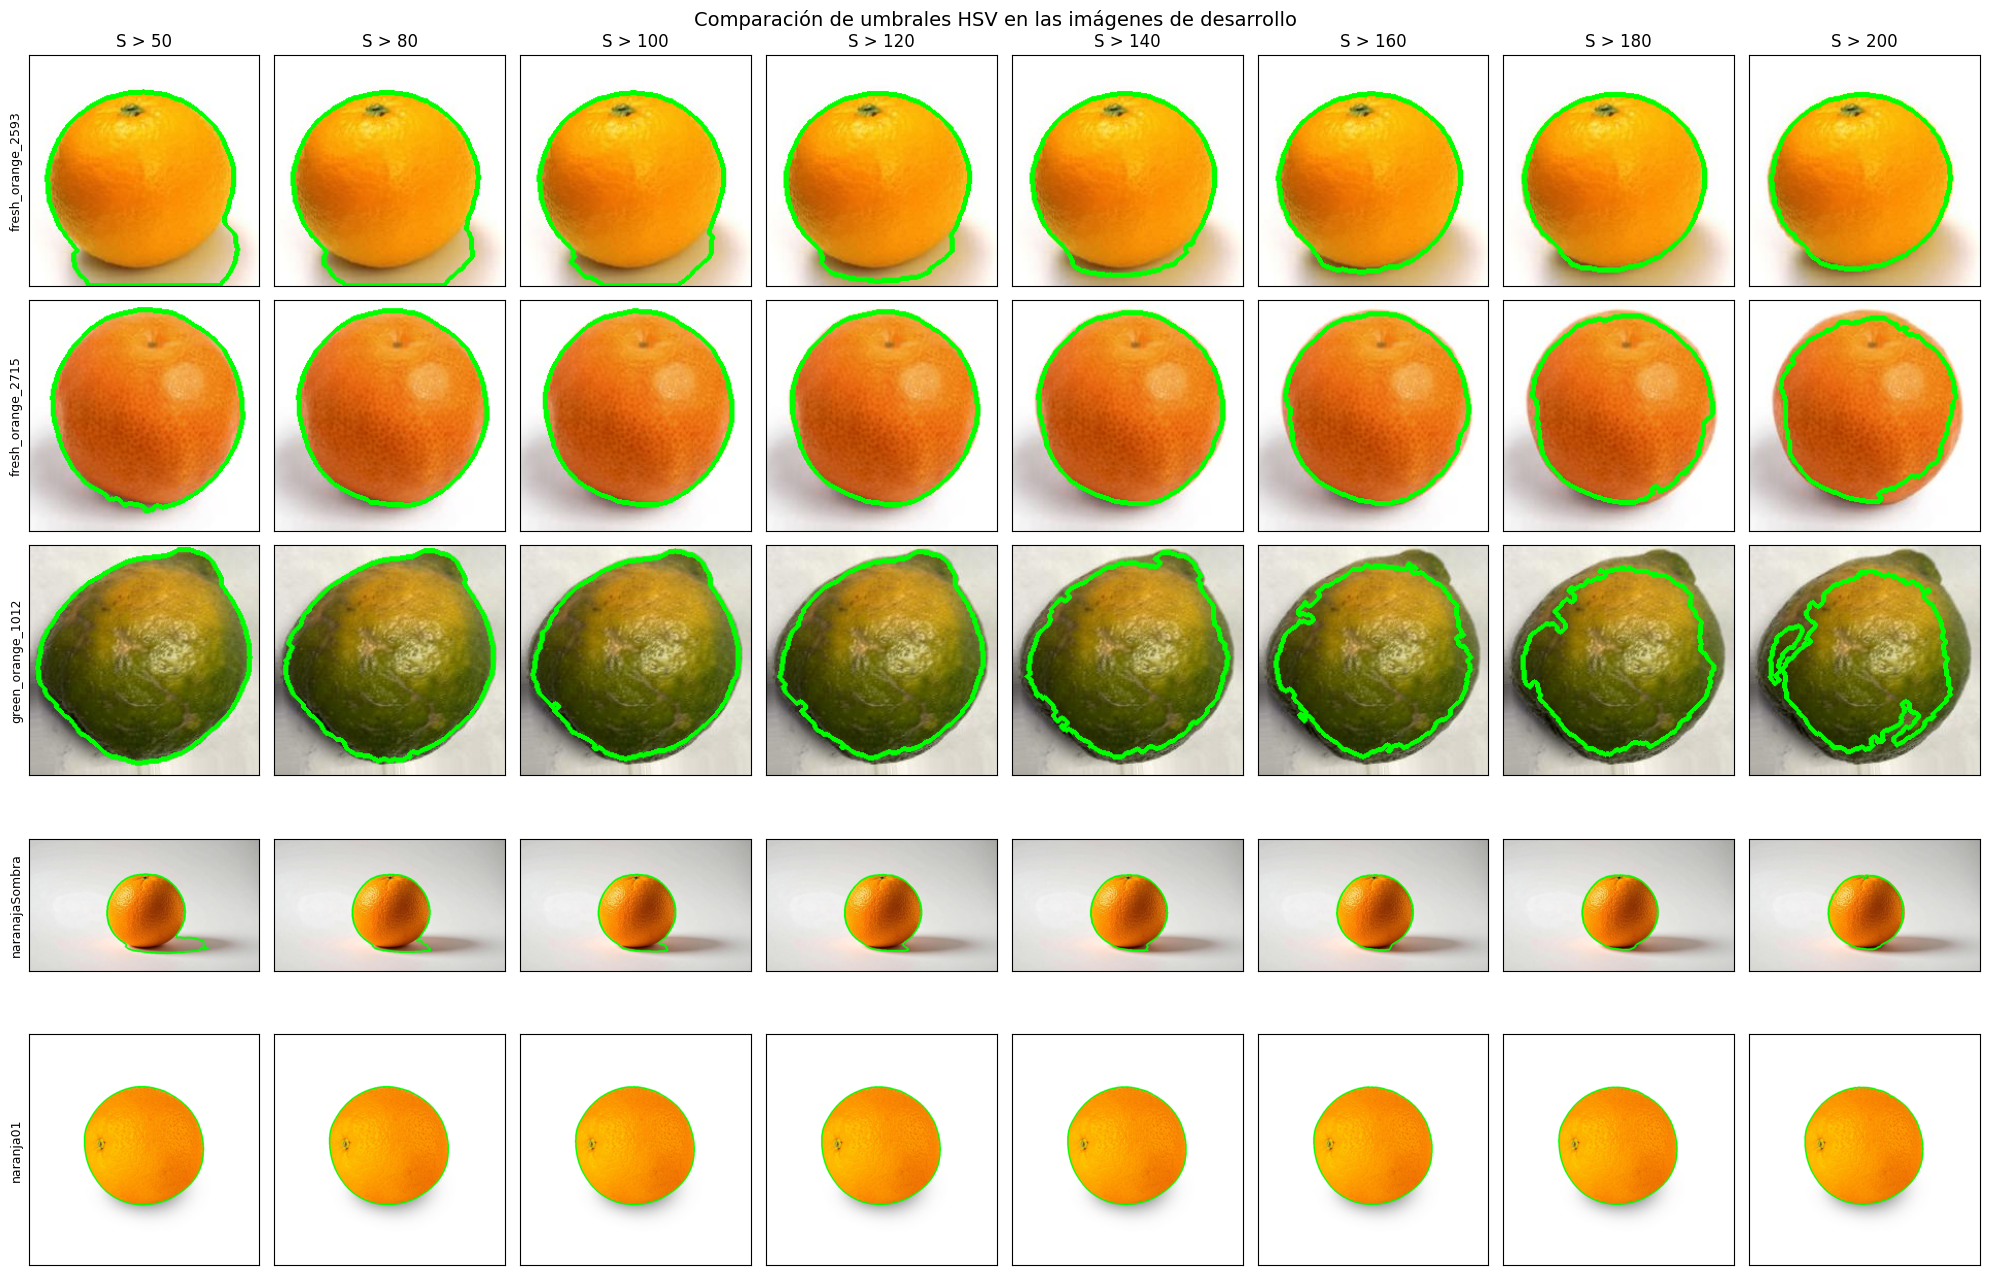

In [12]:

# --------------------------------------------------
# 9.1. COMPARACIÓN DE UMBRALES DE SATURACIÓN
# --------------------------------------------------

# Valores de saturación que vamos a comparar.
umbrales = [50, 80, 100, 120, 140, 160, 180, 200]

# Identificamos las fotografías de desarrollo.
extensiones = {".jpg", ".jpeg", ".png"}

imagenes_desarrollo = sorted(
    ruta for ruta in RUTA_DESARROLLO.iterdir()
    if ruta.is_file() and ruta.suffix.lower() in extensiones
)

print("Fotografías de desarrollo:", len(imagenes_desarrollo))

if len(imagenes_desarrollo) != 5:
    raise ValueError(
        "Se esperaban 5 fotografías en el conjunto de desarrollo."
    )

# Cada fila representa una fotografía.
# Cada columna representa un umbral distinto.
fig, ax = plt.subplots(
    len(imagenes_desarrollo),
    len(umbrales),
    figsize=(20, 13),
    squeeze=False
)

for fila, ruta in enumerate(imagenes_desarrollo):

    for columna, umbral in enumerate(umbrales):

        try:
            # Ejecutamos el mismo algoritmo modificando
            # únicamente el umbral de saturación.
            resultado_prueba = analizar_naranja(
                ruta,
                umbral_s=umbral
            )

            # Mostramos la imagen con el contorno verde.
            ax[fila, columna].imshow(
                resultado_prueba["contorno"]
            )

        except ValueError:
            # Si no existe un contorno válido,
            # dejamos la celda en blanco.
            ax[fila, columna].text(
                0.5, 0.5, "Sin contorno",
                ha="center", va="center"
            )

        # Los títulos indican el valor probado.
        if fila == 0:
            ax[fila, columna].set_title(f"S > {umbral}")

        # Identificamos cada fotografía al lado izquierdo.
        if columna == 0:
            ax[fila, columna].set_ylabel(
                ruta.stem,
                fontsize=9
            )

        ax[fila, columna].set_xticks([])
        ax[fila, columna].set_yticks([])

plt.suptitle(
    "Comparación de umbrales HSV en las imágenes de desarrollo",
    fontsize=14
)

plt.tight_layout()
plt.show()



### 9.2. Selección del umbral definitivo

Durante la implementación inicial se utilizó un umbral de saturación de 50, que permitió construir y verificar el funcionamiento del algoritmo con una fotografía de referencia.

Posteriormente, se evaluaron ocho valores de umbral sobre las cinco fotografías de desarrollo, manteniendo constantes las demás operaciones.

La comparación visual mostró que los umbrales bajos podían incorporar regiones de sombra, mientras que los valores altos podían excluir partes de la fruta, especialmente en las fotografías de naranjas verdes.

Se seleccionó **S > 120** como configuración definitiva, al presentar un equilibrio favorable entre la conservación de la fruta y la exclusión del fondo en las imágenes de desarrollo.

La selección fue cualitativa y no constituye una medición de precisión frente a máscaras de referencia.

El umbral seleccionado se mantendrá constante durante la evaluación de las 45 fotografías.


In [13]:

# --------------------------------------------------
# 9.2. PARÁMETRO SELECCIONADO PARA LA EVALUACIÓN
# --------------------------------------------------

# Valor escogido después de comparar las 5 imágenes
# de desarrollo con diferentes umbrales de saturación.
UMBRAL_FINAL = 120

print(f"Umbral de saturación definitivo: S > {UMBRAL_FINAL}")


Umbral de saturación definitivo: S > 120



## 10. Resultados del conjunto de desarrollo

Una vez seleccionado el umbral de saturación **S > 120**, se aplica el algoritmo a las cinco fotografías de desarrollo.

Se mantienen constantes los demás parámetros: filtro gaussiano de 5 × 5, cierre morfológico con elemento estructurante elíptico de 5 × 5 y cuantización RGB en intervalos de 32 niveles.

Para cada fotografía se obtiene el contorno principal, el color RGB promedio, el intervalo RGB dominante y una representación de la fruta repintada con su color característico.

Esta etapa permite documentar los resultados del conjunto utilizado para desarrollar y ajustar el algoritmo. La evaluación con fotografías adicionales se realizará posteriormente.


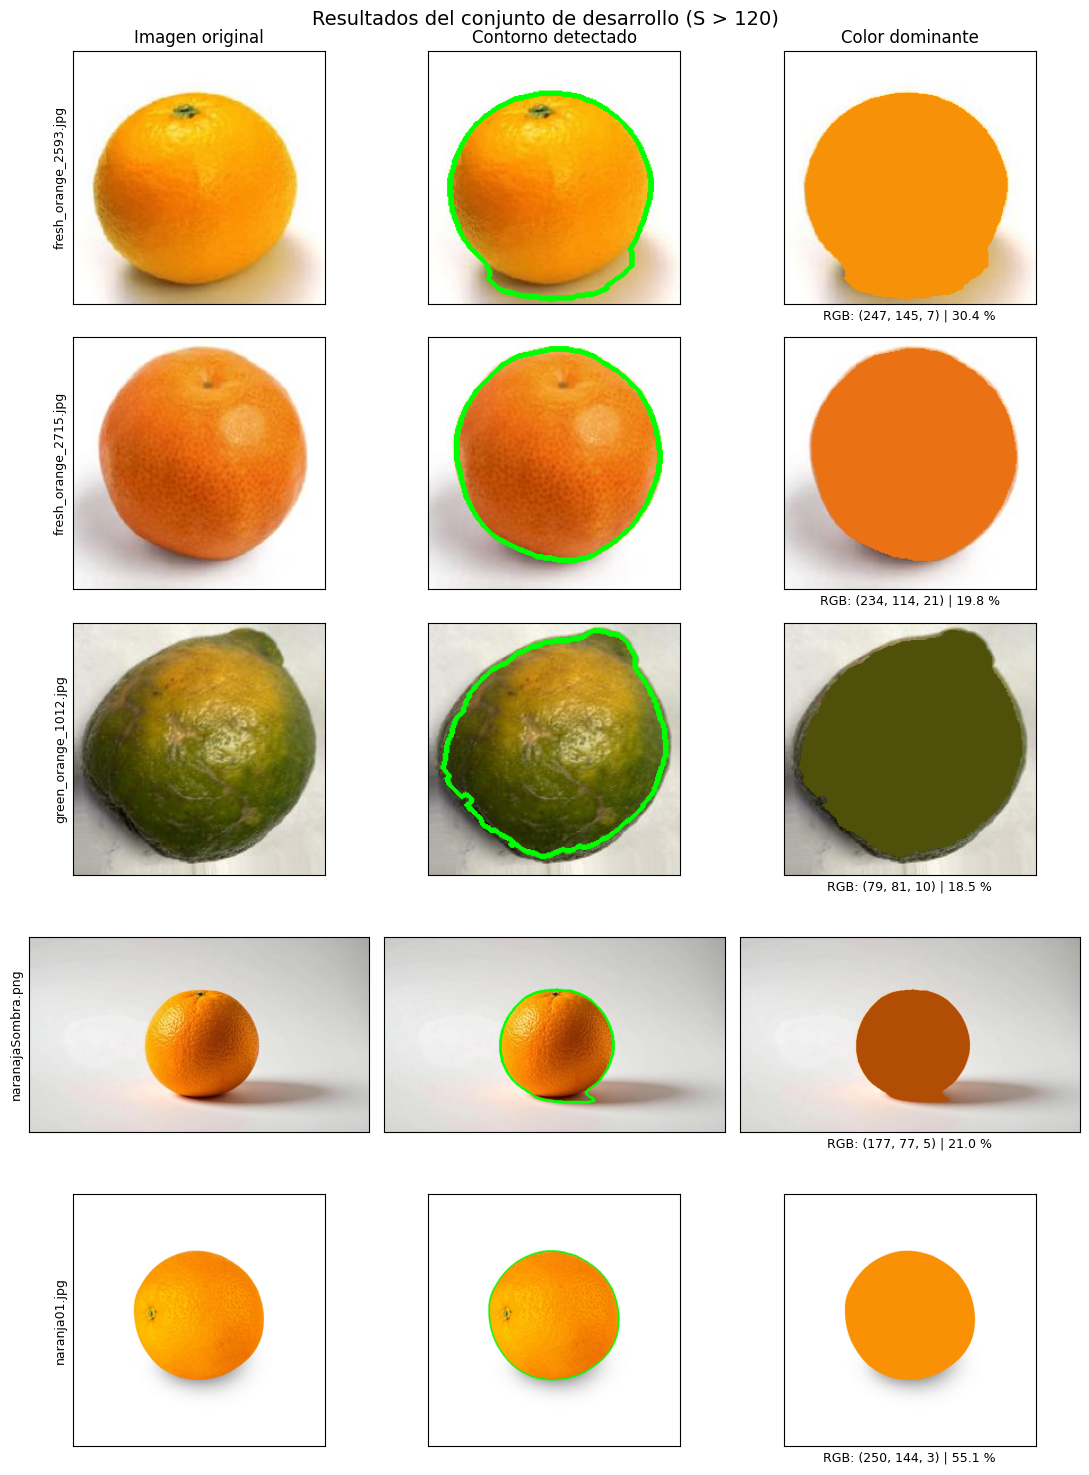

Fotografías procesadas: 5
Figura guardada en: d:\SistemasUniversidad\sistemas8\ProcDImagenes\deteccion_colores_naranjas\resultados\resultados_desarrollo.png


In [14]:

# --------------------------------------------------
# 10. RESULTADOS DE LAS CINCO IMÁGENES DE DESARROLLO
# --------------------------------------------------

resultados_desarrollo = []

# Procesamos las cinco imágenes con el umbral definitivo.
for ruta in imagenes_desarrollo:

    resultado = analizar_naranja(
        ruta,
        umbral_s=UMBRAL_FINAL
    )

    resultados_desarrollo.append(resultado)

# Mostramos tres etapas relevantes por fotografía:
# original, contorno y representación del color dominante.
fig, ax = plt.subplots(
    len(resultados_desarrollo),
    3,
    figsize=(11, 15),
    squeeze=False
)

titulos = [
    "Imagen original",
    "Contorno detectado",
    "Color dominante"
]

for columna, titulo in enumerate(titulos):
    ax[0, columna].set_title(titulo, fontsize=12)

for fila, resultado in enumerate(resultados_desarrollo):

    ax[fila, 0].imshow(resultado["imagen"])
    ax[fila, 1].imshow(resultado["contorno"])
    ax[fila, 2].imshow(resultado["repintada"])

    # Identificamos cada fotografía.
    ax[fila, 0].set_ylabel(
        resultado["nombre"],
        fontsize=9
    )

    # Mostramos el RGB dominante debajo de la tercera imagen.
    rgb = tuple(
        int(round(valor))
        for valor in resultado["rgb_dominante"]
    )

    ax[fila, 2].set_xlabel(
        f"RGB: {rgb} | {resultado['porcentaje']:.1f} %",
        fontsize=9
    )

    for columna in range(3):
        ax[fila, columna].set_xticks([])
        ax[fila, columna].set_yticks([])

plt.suptitle(
    f"Resultados del conjunto de desarrollo (S > {UMBRAL_FINAL})",
    fontsize=14
)

plt.tight_layout()

# Guardamos la figura en alta resolución.
ruta_figura = RUTA_RESULTADOS / "resultados_desarrollo.png"
plt.savefig(ruta_figura, dpi=300, bbox_inches="tight")

plt.show()

print(f"Fotografías procesadas: {len(resultados_desarrollo)}")
print(f"Figura guardada en: {ruta_figura}")


In [15]:

# --------------------------------------------------
# 10.1. TABLA DE RESULTADOS DEL CONJUNTO DE DESARROLLO
# --------------------------------------------------

registros_desarrollo = []

for resultado in resultados_desarrollo:

    promedio = resultado["rgb_promedio"]
    dominante = resultado["rgb_dominante"]

    registros_desarrollo.append({
        "Imagen": resultado["nombre"],
        "R_promedio": round(float(promedio[0]), 2),
        "G_promedio": round(float(promedio[1]), 2),
        "B_promedio": round(float(promedio[2]), 2),
        "R_dominante": round(float(dominante[0]), 2),
        "G_dominante": round(float(dominante[1]), 2),
        "B_dominante": round(float(dominante[2]), 2),
        "Dominante_pct": round(float(resultado["porcentaje"]), 2),
        "Pixeles_ROI": resultado["pixeles"]
    })

tabla_desarrollo = pd.DataFrame(registros_desarrollo)

display(tabla_desarrollo)

# Exportamos los resultados para su posterior consulta.
ruta_csv = RUTA_RESULTADOS / "resultados_desarrollo.csv"

tabla_desarrollo.to_csv(
    ruta_csv,
    index=False,
    encoding="utf-8-sig"
)

print(f"Tabla guardada en: {ruta_csv}")


,Imagen,R_promedio,G_promedio,B_promedio,R_dominante,G_dominante,B_dominante,Dominante_pct,Pixeles_ROI
0,fresh_orange_2593.jpg,232.70,148.30,17.60,247.07,144.80,6.62,30.36,25671
1,fresh_orange_2715.jpg,221.38,115.44,31.52,234.13,113.65,20.58,19.77,26377
2,green_orange_1012.jpg,116.64,104.20,27.31,78.54,80.80,10.40,18.49,28608
3,naranajaSombra.png,205.90,109.10,14.71,177.21,76.62,5.03,21.02,32556
4,naranja01.jpg,249.42,151.59,3.59,250.11,143.70,2.93,55.11,131419


Tabla guardada en: d:\SistemasUniversidad\sistemas8\ProcDImagenes\deteccion_colores_naranjas\resultados\resultados_desarrollo.csv



### 10.2. Análisis de los resultados de desarrollo

La aplicación del algoritmo con un umbral de saturación de 120 permitió identificar el contorno principal de las cinco naranjas y calcular sus características RGB.

Visualmente, los contornos se ajustaron de manera general a la forma de las frutas, tanto en las fotografías anaranjadas como en la verdosa. No obstante, se observaron pequeñas regiones de sombra incorporadas en las imágenes `fresh_orange_2593.jpg` y `naranajaSombra.png`.

Los colores dominantes obtenidos fueron coherentes con las tonalidades observadas: las frutas anaranjadas presentaron valores elevados del canal rojo, mientras que la naranja verde mostró valores más próximos entre los canales rojo y verde.

El porcentaje del intervalo RGB dominante varió entre **18,49 % y 55,11 %**. Esta variación refleja diferencias en la distribución de los colores dentro de las regiones segmentadas y no representa la precisión de la detección.

En conjunto, los resultados muestran que el procedimiento permite extraer el contorno y caracterizar el color de las frutas, aunque su desempeño puede verse afectado por sombras y variaciones de iluminación.

A continuación, se evaluará su comportamiento con **45 fotografías adicionales**, manteniendo constantes los parámetros seleccionados.



## 11. Evaluación experimental

Para evaluar el funcionamiento del algoritmo se utiliza un conjunto de **45 fotografías** que no participaron directamente en el ajuste de los parámetros.

Las imágenes están organizadas en cuatro categorías:

- **Amarillas:** 10 fotografías.
- **Anaranjadas:** 15 fotografías.
- **Sombras:** 10 fotografías.
- **Verdes:** 10 fotografías.

Todas se procesan utilizando el umbral definitivo de saturación **S > 120**, el filtro gaussiano de 5 × 5, el cierre morfológico de 5 × 5 y la cuantización RGB con intervalos de 32 niveles.

Para cada fotografía se obtiene el contorno, la región de interés, el RGB promedio, el intervalo dominante y su frecuencia relativa.

La calidad de la segmentación se revisará visualmente, clasificando los resultados como correctos, parciales o incorrectos. Esta evaluación cualitativa permitirá identificar las principales condiciones en las que el algoritmo presenta dificultades.


In [16]:

# --------------------------------------------------
# 11.1. PROCESAMIENTO DEL CONJUNTO DE EVALUACIÓN
# --------------------------------------------------

# Extensiones de imagen admitidas.
extensiones = {".jpg", ".jpeg", ".png"}

# rglob("*") busca archivos dentro de todas las subcarpetas.
archivos_evaluacion = sorted(
    ruta for ruta in RUTA_EVALUACION.rglob("*")
    if ruta.is_file() and ruta.suffix.lower() in extensiones
)

resultados_evaluacion = []
errores_evaluacion = []

# Aplicamos exactamente la misma configuración a cada foto.
for ruta in archivos_evaluacion:

    try:
        resultado = analizar_naranja(
            ruta,
            umbral_s=UMBRAL_FINAL
        )

        # La categoría corresponde al nombre de la subcarpeta.
        resultado["categoria"] = ruta.parent.name

        resultados_evaluacion.append(resultado)

    except (ValueError, OSError, cv2.error) as error:
        errores_evaluacion.append({
            "imagen": ruta.name,
            "error": str(error)
        })

# Verificamos cuántas imágenes se procesaron.
print(f"Fotografías encontradas: {len(archivos_evaluacion)}")
print(f"Procesadas correctamente: {len(resultados_evaluacion)}")
print(f"Errores de procesamiento: {len(errores_evaluacion)}")

# Comprobamos que las categorías tengan la cantidad esperada.
conteo_categorias = pd.Series(
    [r["categoria"] for r in resultados_evaluacion]
).value_counts()

display(conteo_categorias)

if errores_evaluacion:
    display(pd.DataFrame(errores_evaluacion))

if len(archivos_evaluacion) != 45:
    print("Advertencia: se esperaban 45 fotografías.")


Fotografías encontradas: 45
Procesadas correctamente: 45
Errores de procesamiento: 0


anaranjadas    15
amarillas      10
sombras        10
verdes         10
Name: count, dtype: int64

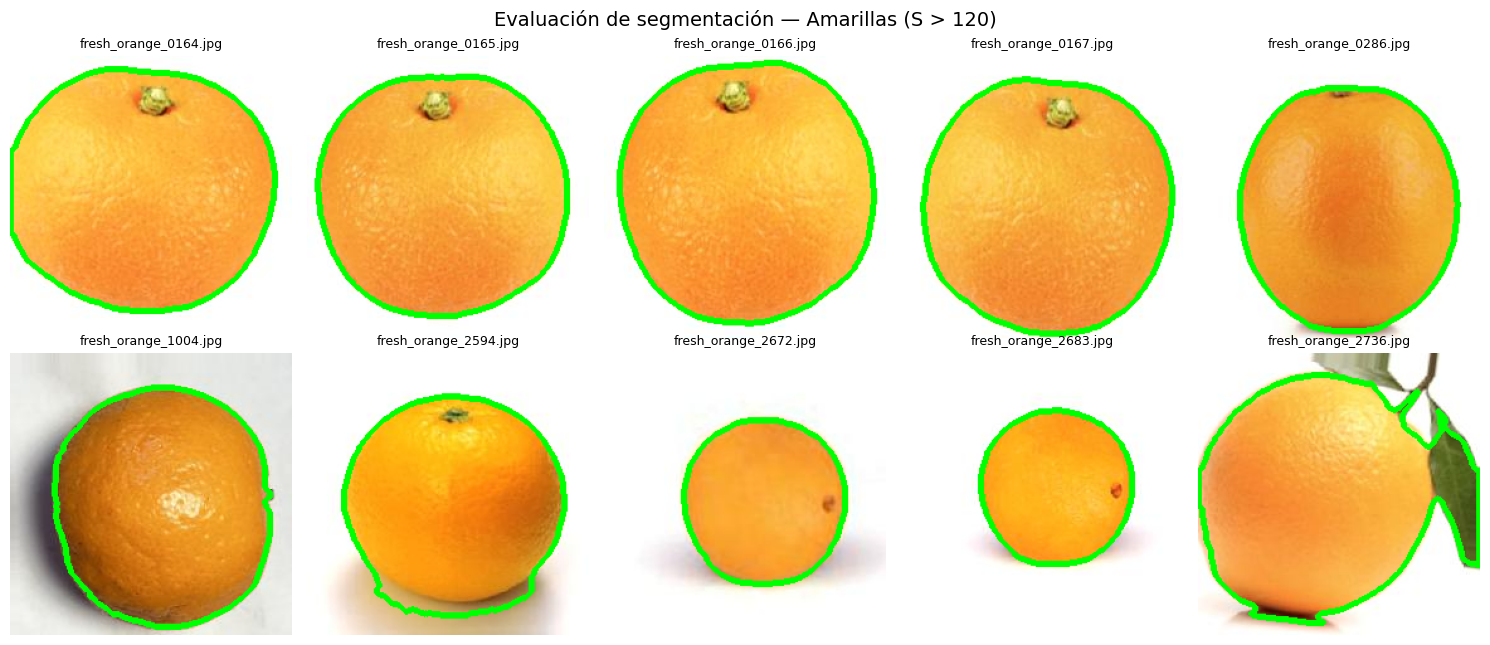

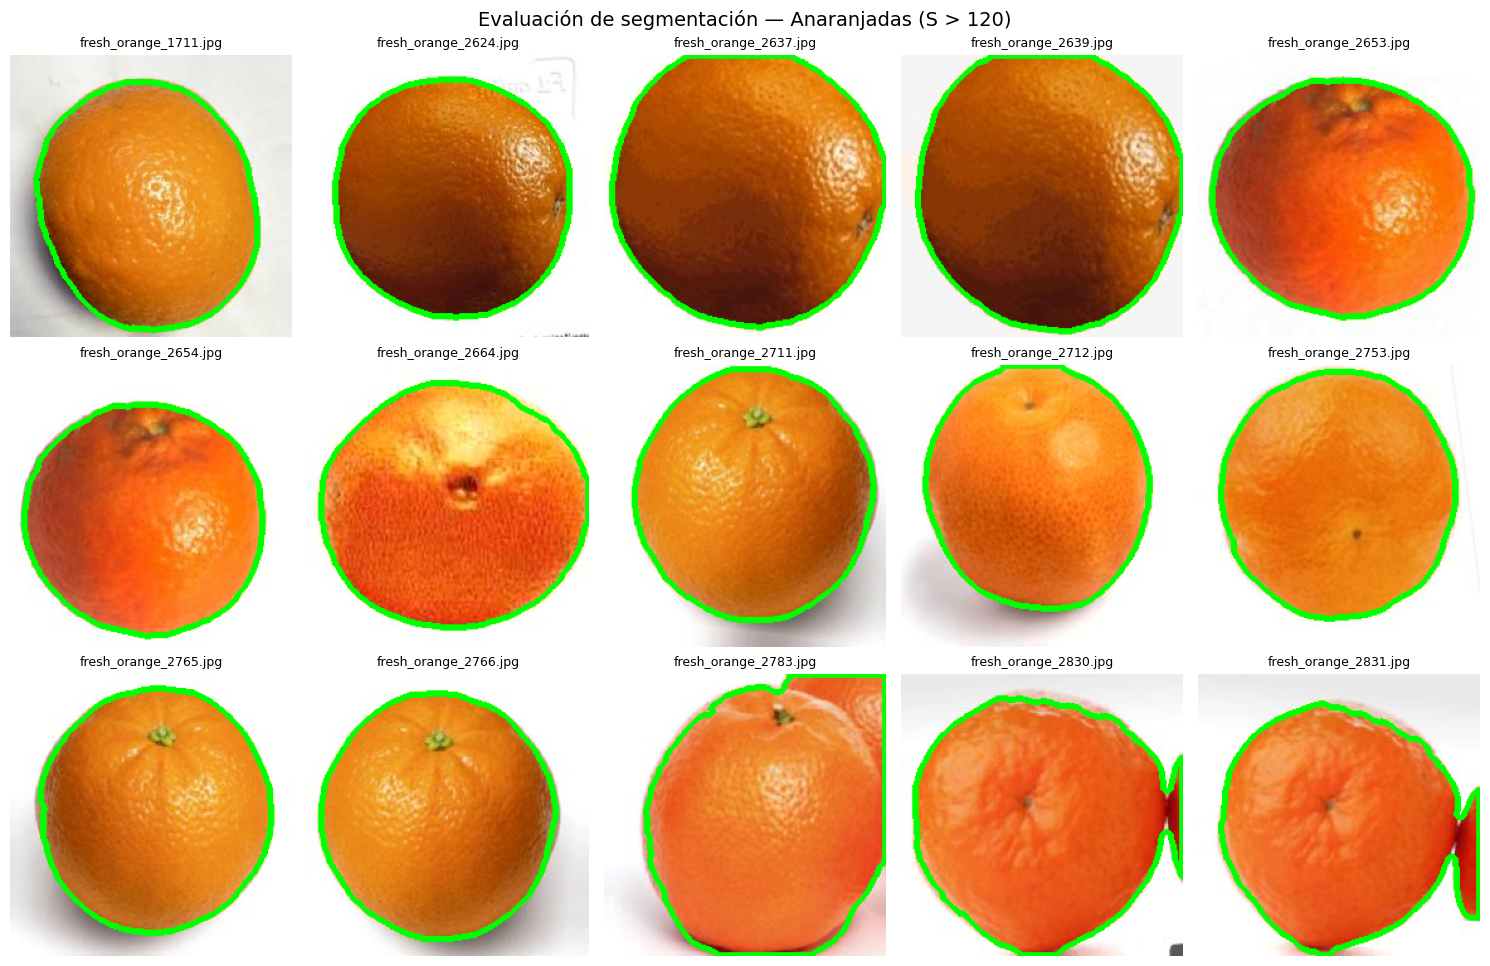

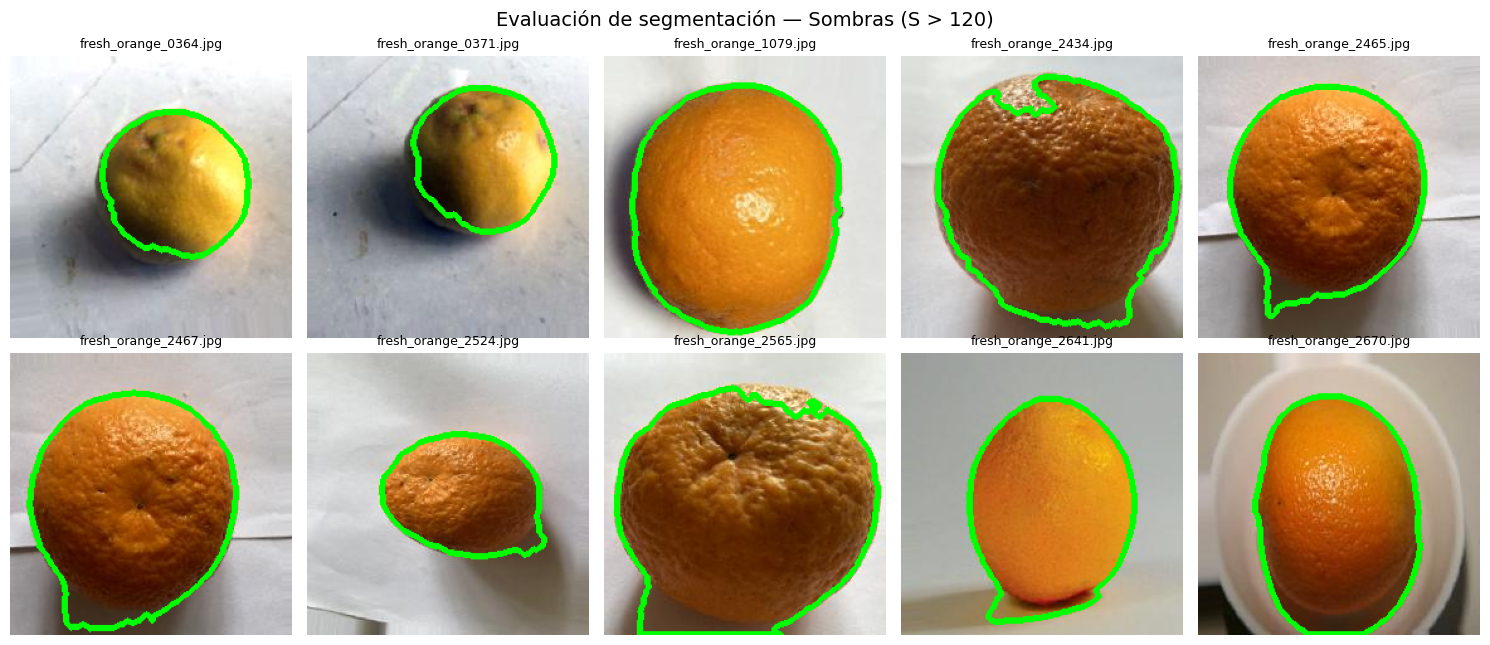

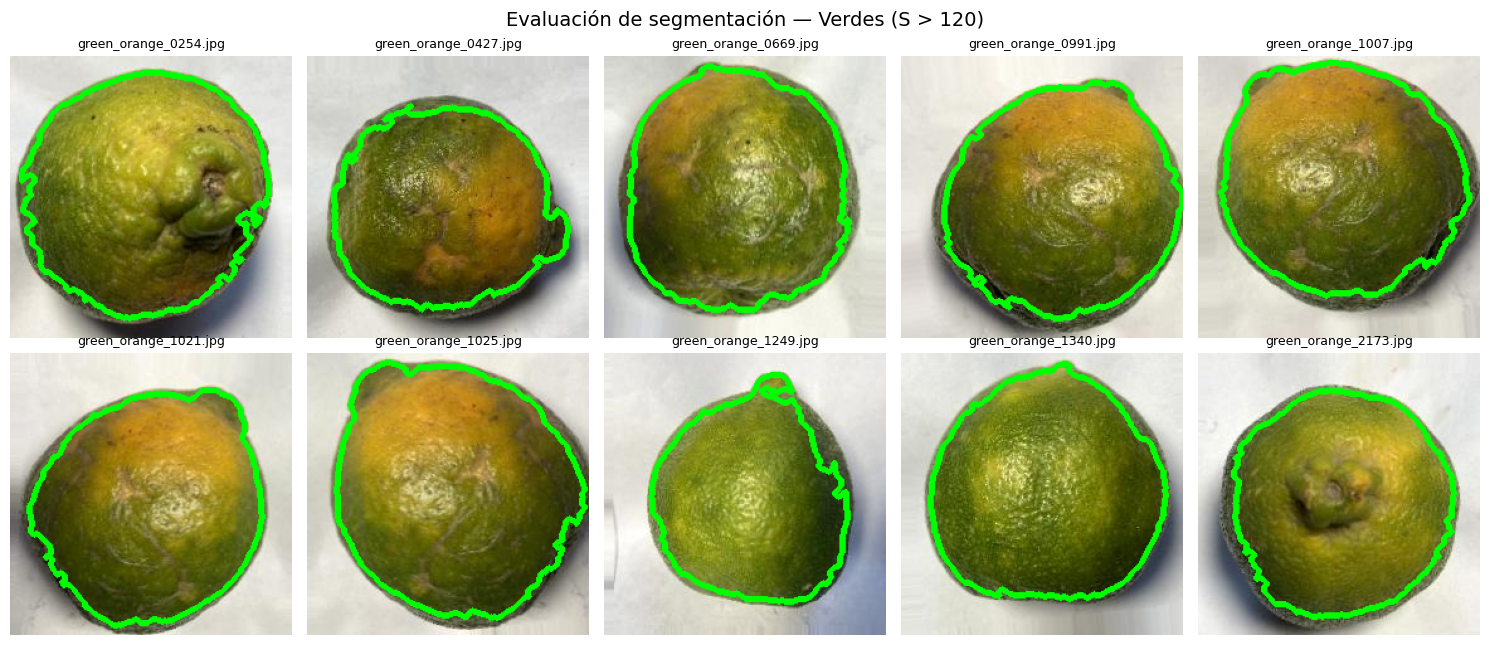

In [17]:

# --------------------------------------------------
# 11.2. INSPECCIÓN VISUAL DE LOS CONTORNOS
# --------------------------------------------------

categorias = ["amarillas", "anaranjadas", "sombras", "verdes"]

for categoria in categorias:

    # Seleccionamos los resultados de una categoría.
    resultados_grupo = [
        r for r in resultados_evaluacion
        if r["categoria"] == categoria
    ]

    if not resultados_grupo:
        continue

    # Organizamos las imágenes en una cuadrícula de 5 columnas.
    columnas = 5
    filas = int(np.ceil(len(resultados_grupo) / columnas))

    fig, ax = plt.subplots(
        filas, columnas,
        figsize=(15, 3.3 * filas),
        squeeze=False
    )

    for eje, resultado in zip(ax.flat, resultados_grupo):
        eje.imshow(resultado["contorno"])
        eje.set_title(resultado["nombre"], fontsize=9)
        eje.axis("off")

    # Ocultamos las posiciones vacías.
    for eje in ax.flat[len(resultados_grupo):]:
        eje.axis("off")

    fig.suptitle(
        f"Evaluación de segmentación — {categoria.capitalize()} "
        f"(S > {UMBRAL_FINAL})",
        fontsize=14
    )

    plt.tight_layout()

    # Guardamos cada figura para documentar la evaluación.
    ruta_figura = (
        RUTA_RESULTADOS / f"contornos_{categoria}.png"
    )

    plt.savefig(
        ruta_figura,
        dpi=250,
        bbox_inches="tight"
    )

    plt.show()



### 11.3. Observaciones preliminares de la evaluación

La inspección visual de las 45 fotografías procesadas con **S > 120** mostró diferencias en el comportamiento del algoritmo según las condiciones de las imágenes.

Las fotografías amarillas y anaranjadas presentaron, en general, contornos bien definidos. Sin embargo, se identificaron dificultades cuando existían hojas, frutas adyacentes o pequeñas regiones de sombra conectadas al objeto.

En el grupo de sombras se observaron mejoras respecto a las pruebas iniciales con un umbral de 50, aunque persistieron irregularidades en algunas fotografías.

En las naranjas verdes, el algoritmo logró identificar la región principal, pero algunos bordes mostraron pequeñas pérdidas debido a variaciones de saturación.

Estos resultados evidencian que la segmentación basada únicamente en el canal de saturación tiene limitaciones ante fondos complejos y condiciones variables de iluminación.

El umbral de 120 se mantuvo constante durante toda la evaluación, sin realizar ajustes individuales por fotografía.



### 11.4. Clasificación visual de la segmentación

Se realizó una revisión cualitativa de los contornos obtenidos en las 45 fotografías de evaluación, utilizando tres categorías:

- **Correcta:** el contorno delimita adecuadamente la fruta.
- **Parcial:** existen pequeñas pérdidas de superficie o regiones externas incorporadas.
- **Incorrecta:** se excluye una parte importante de la fruta o se incorpora una región considerable del fondo.

Esta clasificación permite identificar fortalezas y limitaciones de la segmentación, pero no constituye una medida de exactitud a nivel de píxel, puesto que no se dispone de máscaras de referencia.


In [18]:

# --------------------------------------------------
# 11.4. CLASIFICACIÓN VISUAL DE LOS CONTORNOS
# --------------------------------------------------

# Fotografías clasificadas visualmente como parciales o incorrectas.
etiquetas_especiales = {
    "amarillas": {
        "Parcial": ["fresh_orange_2594.jpg"],
        "Incorrecta": ["fresh_orange_2736.jpg"]
    },
    "anaranjadas": {
        "Parcial": [
            "fresh_orange_2830.jpg",
            "fresh_orange_2831.jpg"
        ],
        "Incorrecta": ["fresh_orange_2783.jpg"]
    },
    "sombras": {
        "Parcial": [
            "fresh_orange_2434.jpg",
            "fresh_orange_2465.jpg",
            "fresh_orange_2467.jpg",
            "fresh_orange_2524.jpg",
            "fresh_orange_2565.jpg"
        ]
    },
    "verdes": {
        "Parcial": [
            "green_orange_0254.jpg",
            "green_orange_0427.jpg",
            "green_orange_0991.jpg",
            "green_orange_1249.jpg",
            "green_orange_2173.jpg"
        ]
    }
}

# Fotografías revisadas y clasificadas como correctas.
etiquetas_correctas = {
    "amarillas": [
        "fresh_orange_0164.jpg",
        "fresh_orange_0165.jpg",
        "fresh_orange_0166.jpg",
        "fresh_orange_0167.jpg",
        "fresh_orange_0286.jpg",
        "fresh_orange_1004.jpg",
        "fresh_orange_2672.jpg",
        "fresh_orange_2683.jpg"
    ],
    "anaranjadas": [
        "fresh_orange_1711.jpg",
        "fresh_orange_2624.jpg",
        "fresh_orange_2637.jpg",
        "fresh_orange_2639.jpg",
        "fresh_orange_2653.jpg",
        "fresh_orange_2654.jpg",
        "fresh_orange_2664.jpg",
        "fresh_orange_2711.jpg",
        "fresh_orange_2712.jpg",
        "fresh_orange_2753.jpg",
        "fresh_orange_2765.jpg",
        "fresh_orange_2766.jpg"
    ],
    "sombras": [
        "fresh_orange_0364.jpg",
        "fresh_orange_0371.jpg",
        "fresh_orange_1079.jpg",
        "fresh_orange_2641.jpg",
        "fresh_orange_2670.jpg"
    ],
    "verdes": [
        "green_orange_0669.jpg",
        "green_orange_1007.jpg",
        "green_orange_1021.jpg",
        "green_orange_1025.jpg",
        "green_orange_1340.jpg"
    ]
}

# Unificamos todas las etiquetas en un diccionario.
clasificacion_visual = {}

for categoria, nombres in etiquetas_correctas.items():
    for nombre in nombres:
        clasificacion_visual[(categoria, nombre)] = "Correcta"

for categoria, estados in etiquetas_especiales.items():
    for estado, nombres in estados.items():
        for nombre in nombres:
            clave = (categoria, nombre)

            if clave in clasificacion_visual:
                raise ValueError(f"Etiqueta duplicada: {clave}")

            clasificacion_visual[clave] = estado

# Asignamos la clasificación previamente registrada.
for resultado in resultados_evaluacion:

    clave = (resultado["categoria"], resultado["nombre"])

    # Una fotografía nueva queda pendiente de revisión.
    resultado["segmentacion"] = clasificacion_visual.get(
        clave, "Pendiente"
    )

# Comprobamos que todas las fotografías estén clasificadas.
pendientes = [
    r["nombre"] for r in resultados_evaluacion
    if r["segmentacion"] == "Pendiente"
]

if pendientes:
    raise ValueError(f"Fotografías sin evaluar: {pendientes}")

# Elaboramos el resumen.
tabla_clasificacion = pd.DataFrame([
    {
        "Categoria": r["categoria"],
        "Imagen": r["nombre"],
        "Segmentacion": r["segmentacion"]
    }
    for r in resultados_evaluacion
])

resumen_segmentacion = pd.crosstab(
    tabla_clasificacion["Categoria"],
    tabla_clasificacion["Segmentacion"]
).reindex(
    index=["amarillas", "anaranjadas", "sombras", "verdes"],
    columns=["Correcta", "Parcial", "Incorrecta"],
    fill_value=0
)

display(resumen_segmentacion)

print(f"Fotografías clasificadas: {len(tabla_clasificacion)}")


Segmentacion,Correcta,Parcial,Incorrecta
Categoria,,,
amarillas,8,1,1
anaranjadas,12,2,1
sombras,5,5,0
verdes,5,5,0


Fotografías clasificadas: 45



## 12. Análisis estadístico de los resultados

A partir de las 45 fotografías de evaluación se construye una tabla con los valores RGB promedio, el color dominante, el porcentaje del intervalo dominante y la calidad visual de la segmentación.

El análisis descriptivo comprende:

1. La distribución de segmentaciones correctas, parciales e incorrectas.
2. El porcentaje promedio del intervalo RGB dominante en cada categoría.
3. Los valores RGB promedio de las regiones segmentadas.

Las estadísticas incluyen inicialmente todas las fotografías. Posteriormente, se examinan por separado las imágenes con segmentación visualmente correcta para reducir la influencia de errores importantes en las máscaras.

El porcentaje dominante mide la concentración de los píxeles en el intervalo RGB más frecuente y no constituye una medida de exactitud de la segmentación.


In [19]:

# --------------------------------------------------
# 12.1. TABLA DE RESULTADOS DE EVALUACIÓN
# --------------------------------------------------

registros = []

for resultado in resultados_evaluacion:

    promedio = resultado["rgb_promedio"]
    dominante = resultado["rgb_dominante"]

    registros.append({
        "Imagen": resultado["nombre"],
        "Categoria": resultado["categoria"],
        "R_promedio": round(float(promedio[0]), 2),
        "G_promedio": round(float(promedio[1]), 2),
        "B_promedio": round(float(promedio[2]), 2),
        "R_dominante": round(float(dominante[0]), 2),
        "G_dominante": round(float(dominante[1]), 2),
        "B_dominante": round(float(dominante[2]), 2),
        "Porcentaje_dominante": round(
            float(resultado["porcentaje"]), 2
        ),
        "Pixeles_ROI": resultado["pixeles"],
        "Segmentacion": resultado["segmentacion"]
    })

tabla_resultados = pd.DataFrame(registros)

# Guardamos el conjunto completo de mediciones.
ruta_csv = RUTA_RESULTADOS / "resultados_evaluacion.csv"

tabla_resultados.to_csv(
    ruta_csv,
    index=False,
    encoding="utf-8-sig"
)

display(tabla_resultados.head(10))

print(f"Registros guardados: {len(tabla_resultados)}")
print(f"Archivo: {ruta_csv}")


,Imagen,Categoria,R_promedio,G_promedio,B_promedio,R_dominante,G_dominante,B_dominante,Porcentaje_dominante,Pixeles_ROI,Segmentacion
0,fresh_orange_0164.jpg,amarillas,250.65,175.13,65.55,251.98,172.60,58.20,28.93,32916,Correcta
1,fresh_orange_0165.jpg,amarillas,247.56,172.22,64.17,248.29,172.19,57.81,29.87,30801,Correcta
2,fresh_orange_0166.jpg,amarillas,250.39,173.40,61.04,252.17,174.03,55.70,36.14,33764,Correcta
3,fresh_orange_0167.jpg,amarillas,246.08,171.56,63.93,247.05,172.26,58.01,30.67,32123,Correcta
4,fresh_orange_0286.jpg,amarillas,236.36,151.46,48.58,235.80,144.26,41.32,46.28,26946,Correcta
5,fresh_orange_1004.jpg,amarillas,204.27,126.32,33.50,235.41,150.15,38.31,20.56,26359,Correcta
6,fresh_orange_2594.jpg,amarillas,237.24,155.20,25.74,253.37,174.33,18.23,29.37,24137,Parcial
7,fresh_orange_2672.jpg,amarillas,245.38,162.15,54.05,251.16,167.28,50.43,52.45,13507,Correcta
8,fresh_orange_2683.jpg,amarillas,252.09,170.70,33.02,253.98,171.80,26.79,51.20,11834,Correcta
9,fresh_orange_2736.jpg,amarillas,230.78,163.40,69.06,250.60,177.30,73.44,24.14,31153,Incorrecta


Registros guardados: 45
Archivo: d:\SistemasUniversidad\sistemas8\ProcDImagenes\deteccion_colores_naranjas\resultados\resultados_evaluacion.csv


Estadísticas de las 45 imágenes:


,Imagenes,R_promedio,G_promedio,B_promedio,Dominante_pct
Categoria,,,,,
amarillas,10,240.08,162.15,51.86,34.96
anaranjadas,15,211.42,106.85,30.71,26.57
sombras,10,154.42,93.39,27.52,19.01
verdes,10,112.68,108.66,29.87,18.66


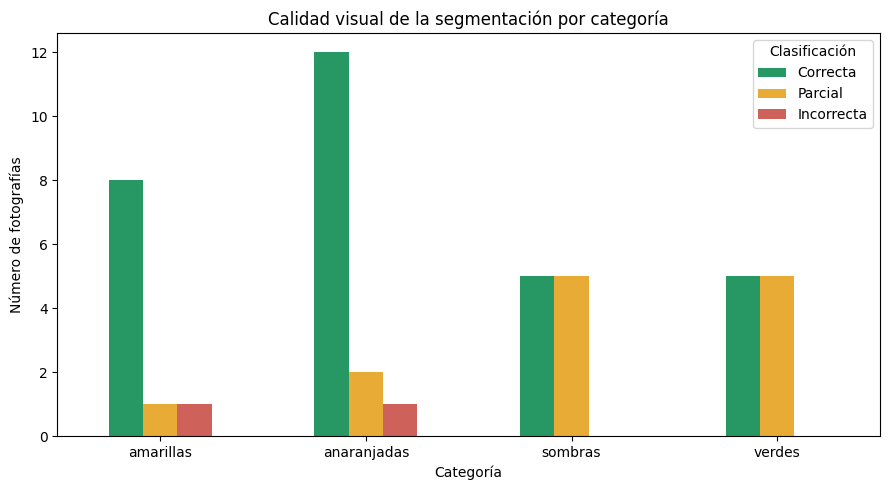

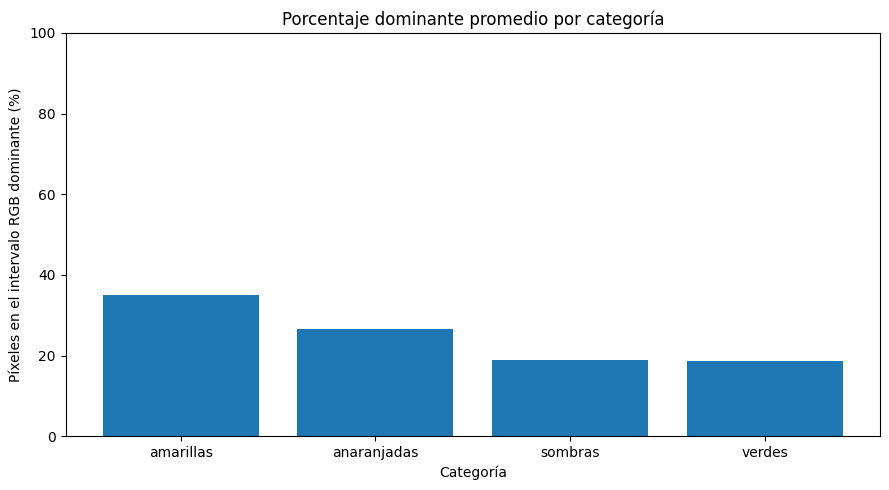

In [20]:

# --------------------------------------------------
# 12.2. ESTADÍSTICAS Y VISUALIZACIÓN
# --------------------------------------------------

orden = ["amarillas", "anaranjadas", "sombras", "verdes"]

# Estadísticas descriptivas por categoría.
estadisticas = tabla_resultados.groupby("Categoria").agg(
    Imagenes=("Imagen", "count"),
    R_promedio=("R_promedio", "mean"),
    G_promedio=("G_promedio", "mean"),
    B_promedio=("B_promedio", "mean"),
    Dominante_pct=("Porcentaje_dominante", "mean")
).reindex(orden).round(2)

print("Estadísticas de las 45 imágenes:")
display(estadisticas)

# GRÁFICA 1: CALIDAD DE LA SEGMENTACIÓN

conteos = pd.crosstab(
    tabla_resultados["Categoria"],
    tabla_resultados["Segmentacion"]
).reindex(
    index=orden,
    columns=["Correcta", "Parcial", "Incorrecta"],
    fill_value=0
)

ax = conteos.plot(
    kind="bar",
    figsize=(9, 5),
    color=["#279764", "#e8ab35", "#ce615a"]
)

ax.set_title("Calidad visual de la segmentación por categoría")
ax.set_xlabel("Categoría")
ax.set_ylabel("Número de fotografías")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Clasificación")

plt.tight_layout()
plt.savefig(
    RUTA_RESULTADOS / "calidad_segmentacion.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# GRÁFICA 2: PORCENTAJE DEL INTERVALO RGB DOMINANTE

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    estadisticas.index,
    estadisticas["Dominante_pct"]
)

ax.set_title("Porcentaje dominante promedio por categoría")
ax.set_xlabel("Categoría")
ax.set_ylabel("Píxeles en el intervalo RGB dominante (%)")
ax.set_ylim(0, 100)

plt.tight_layout()
plt.savefig(
    RUTA_RESULTADOS / "porcentaje_dominante.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [21]:

# --------------------------------------------------
# 12.3. ANÁLISIS DE SEGMENTACIONES CORRECTAS
# --------------------------------------------------

# Filtramos los registros con segmentación visualmente correcta.
datos_correctos = tabla_resultados[
    tabla_resultados["Segmentacion"] == "Correcta"
]

resumen_correctos = datos_correctos.groupby("Categoria").agg(
    Imagenes=("Imagen", "count"),
    R=("R_promedio", "mean"),
    G=("G_promedio", "mean"),
    B=("B_promedio", "mean"),
    Dominante_pct=("Porcentaje_dominante", "mean")
).reindex(
    ["amarillas", "anaranjadas", "sombras", "verdes"]
).round(2)

print("Resultados de las segmentaciones correctas:")
display(resumen_correctos)

print(
    f"Fotografías con segmentación correcta: "
    f"{len(datos_correctos)} de {len(tabla_resultados)}"
)


Resultados de las segmentaciones correctas:


,Imagenes,R,G,B,Dominante_pct
Categoria,,,,,
amarillas,8,241.60,162.87,52.98,37.01
anaranjadas,12,206.01,106.87,27.45,23.80
sombras,5,176.74,114.95,32.14,16.91
verdes,5,113.22,108.33,30.66,18.30


Fotografías con segmentación correcta: 30 de 45



### 12.4. Interpretación de los resultados

La evaluación de 45 fotografías con el umbral **S > 120** produjo 30 segmentaciones visualmente correctas (66,7 %), 13 parciales (28,9 %) y 2 incorrectas (4,4 %).

El mejor comportamiento se observó en las fotografías anaranjadas, con 12 de 15 segmentaciones correctas. Las principales dificultades aparecieron en imágenes con sombras intensas, hojas, frutas adyacentes y regiones de baja saturación, especialmente en las naranjas verdes.

El análisis RGB permitió identificar diferencias entre las tonalidades de las frutas. En las imágenes correctamente segmentadas, las amarillas presentaron valores promedio cercanos a (242, 163, 53), las anaranjadas a (206, 107, 27) y las verdes a (113, 108, 31).

El porcentaje promedio del intervalo RGB dominante fue mayor en las fotografías amarillas (34,96 %) y menor en las verdes (18,66 %) y en aquellas con sombras (19,01 %). Estas diferencias describen la distribución de los colores dentro de las regiones segmentadas y no representan la precisión del algoritmo.

En general, los resultados demuestran que la combinación de segmentación HSV, cierre morfológico y cuantización RGB permite identificar el contorno y caracterizar el color predominante de las frutas en distintas condiciones. No obstante, el método presenta limitaciones cuando el objeto y el fondo tienen características de saturación similares.

La evaluación visual es cualitativa; para obtener medidas de exactitud sería necesario disponer de máscaras de referencia y calcular métricas como IoU o Dice.



## 13. Comparación visual de los colores dominantes

Para representar los resultados del algoritmo se seleccionan tres fotografías del conjunto de evaluación, correspondientes a naranjas amarillentas, anaranjadas y verdes.

En cada caso se compara la fotografía original con la imagen obtenida al reemplazar los píxeles de la región segmentada por el color RGB dominante.

Las tres fotografías fueron procesadas con los mismos parámetros, incluyendo el umbral de saturación de 120 y la cuantización RGB en intervalos de 32 niveles.

Esta representación permite visualizar las diferencias cromáticas identificadas por el algoritmo y comprobar que el color dominante se calcula a partir de cada fotografía, sin establecer previamente un color específico para la fruta.


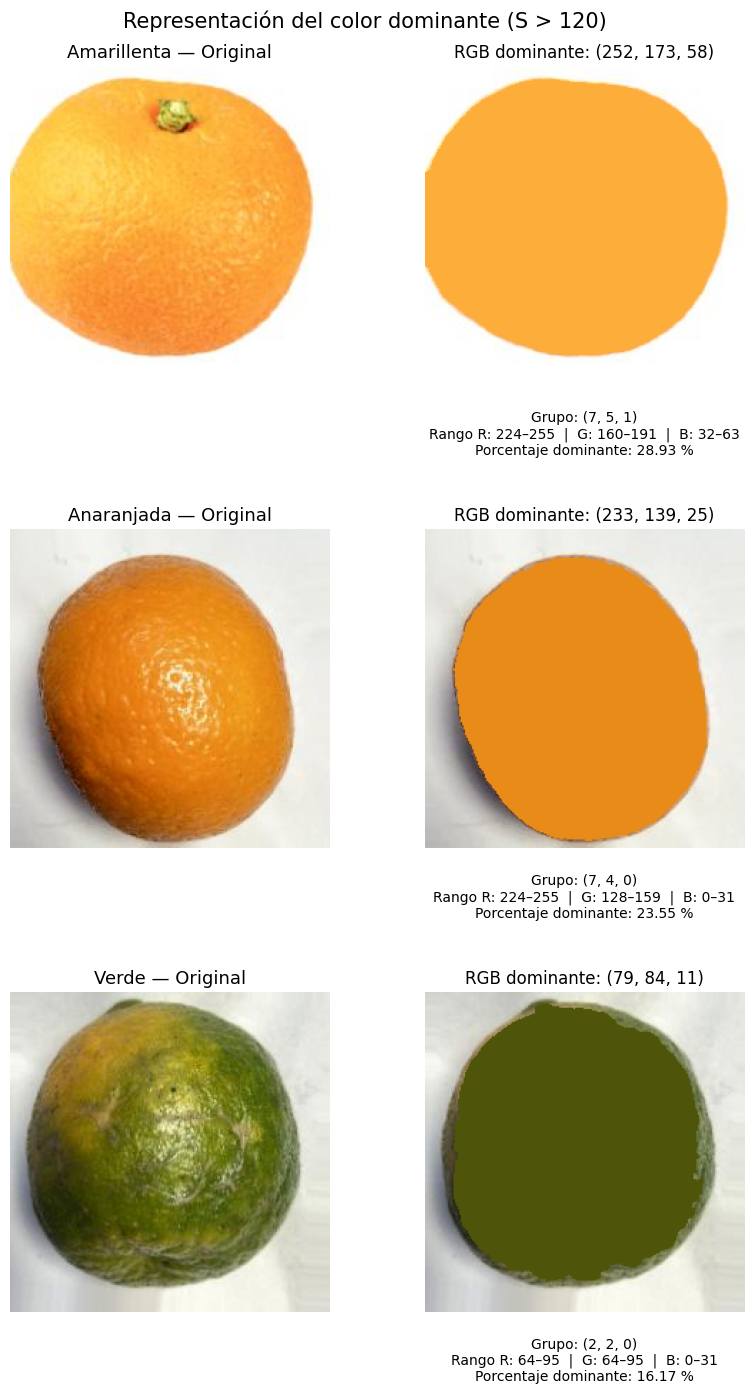

Figura guardada en: d:\SistemasUniversidad\sistemas8\ProcDImagenes\deteccion_colores_naranjas\resultados\comparacion_colores_final.png


In [22]:

# --------------------------------------------------
# 13. COMPARACIÓN VISUAL DEL COLOR DOMINANTE
# --------------------------------------------------

seleccion = {
    "Amarillenta": "fresh_orange_0164.jpg",
    "Anaranjada": "fresh_orange_1711.jpg",
    "Verde": "green_orange_0669.jpg"
}

fig, ax = plt.subplots(3, 2, figsize=(10, 14))

for fila, (categoria, nombre) in enumerate(seleccion.items()):

    # Recuperamos la imagen previamente procesada.
    resultado = next(
        r for r in resultados_evaluacion
        if r["nombre"] == nombre
    )

    # RGB representativo del intervalo dominante.
    rgb = tuple(
        int(round(v)) for v in resultado["rgb_dominante"]
    )

    # Límites del intervalo RGB.
    rango_inf = tuple(
        int(v) for v in resultado["rango_inferior"]
    )
    rango_sup = tuple(
        int(v) for v in resultado["rango_superior"]
    )

    # Grupo RGB recuperado a partir del límite inferior.
    grupo = tuple(v // 32 for v in rango_inf)

    # Porcentaje de píxeles del intervalo dominante.
    porcentaje = float(resultado["porcentaje"])

    # Imagen original.
    ax[fila, 0].imshow(resultado["imagen"])
    ax[fila, 0].set_title(
        f"{categoria} — Original",
        fontsize=13
    )
    ax[fila, 0].axis("off")

    # Imagen repintada.
    ax[fila, 1].imshow(resultado["repintada"])
    ax[fila, 1].set_title(
        f"RGB dominante: {rgb}",
        fontsize=12
    )
    ax[fila, 1].axis("off")

    # Información cuantitativa del intervalo dominante.
    texto = (
        f"Grupo: {grupo}\n"
        f"Rango R: {rango_inf[0]}–{rango_sup[0]}  |  "
        f"G: {rango_inf[1]}–{rango_sup[1]}  |  "
        f"B: {rango_inf[2]}–{rango_sup[2]}\n"
        f"Porcentaje dominante: {porcentaje:.2f} %"
    )

    ax[fila, 1].text(
        0.5, -0.08,
        texto,
        transform=ax[fila, 1].transAxes,
        ha="center",
        va="top",
        fontsize=10
    )

plt.suptitle(
    f"Representación del color dominante (S > {UMBRAL_FINAL})",
    fontsize=15
)

# Dejamos espacio para la información debajo de cada imagen.
plt.subplots_adjust(
    top=0.94,
    bottom=0.05,
    hspace=0.45,
    wspace=0.15
)

# Guardamos la figura actualizada.
ruta_comparacion = (
    RUTA_RESULTADOS / "comparacion_colores_final.png"
)

plt.savefig(
    ruta_comparacion,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Figura guardada en: {ruta_comparacion}")



### 13.1. Interpretación de la comparación visual

La comparación muestra que el algoritmo identifica colores dominantes diferentes en fotografías de naranjas amarillentas, anaranjadas y verdes, obteniendo valores RGB de (252, 173, 58), (233, 139, 25) y (79, 84, 11), respectivamente.

Las representaciones repintadas permiten visualizar el color calculado y verificar la región segmentada. En la fotografía verde se observan pequeñas zonas de la superficie original que no fueron incluidas en la máscara, lo que evidencia una limitación del umbral de saturación seleccionado.

Estos resultados muestran la capacidad del procedimiento para caracterizar diferentes tonalidades, aunque la calidad de la representación depende de la segmentación inicial.



## 14. Conclusiones y trabajo futuro

### Conclusiones

1. Se desarrolló un algoritmo de procesamiento digital de imágenes que integra filtrado gaussiano, segmentación por saturación HSV, cierre morfológico y detección de contornos para identificar la región principal de una naranja.

2. La comparación de umbrales realizada con cinco fotografías de desarrollo permitió seleccionar **S > 120** como parámetro definitivo, al ofrecer un equilibrio favorable entre la conservación de la fruta y la exclusión de regiones del fondo.

3. Durante la evaluación de 45 fotografías se obtuvieron **30 segmentaciones visualmente correctas (66,7 %), 13 parciales (28,9 %) y 2 incorrectas (4,4 %)**. Estos resultados corresponden a una evaluación cualitativa, no a una medición de exactitud por píxel.

4. El análisis RGB permitió caracterizar diferentes tonalidades de las frutas. Mediante cuantización en intervalos de 32 niveles por canal fue posible identificar el rango RGB más frecuente y calcular un color representativo de cada imagen.

5. Las principales limitaciones se relacionaron con sombras, objetos cercanos y regiones de baja saturación, que pueden alterar la delimitación de la fruta y los valores RGB calculados.

### Trabajo futuro

Como posibles mejoras se propone explorar:

- **Umbralización multicanal HSV:** para combinar información de tono, saturación y luminosidad.
- **K-Means:** para agrupar píxeles según sus características de color, sin depender exclusivamente de intervalos RGB fijos.
- **Espacio de color CIELAB:** para analizar diferencias cromáticas de una manera más relacionada con la percepción visual.
- **Métodos de segmentación más robustos:** como GrabCut, especialmente en fotografías con sombras y fondos complejos.
- **Evaluación cuantitativa:** mediante máscaras de referencia y métricas como IoU o Dice.

Estas alternativas se plantean como trabajo futuro y no forman parte del algoritmo implementado.

### Consideración final

El proyecto demuestra que las técnicas clásicas de procesamiento digital de imágenes permiten extraer información relevante de fotografías de frutas mediante procedimientos relativamente sencillos, interpretables y reproducibles.
